# TerraVista — Five-Recipe Augmentation Comparison (Validation Only)

**Goal:** compare exactly five train-time augmentation recipes with the same ResNet-50 training procedure and the same fixed seeds. Model selection uses validation macro-F1. **Test paths are never resolved; test images and test metrics are not used.**

## The five recipes

1. **`00_no_augmentation`** — all seven application probabilities are zero.
2. **`01_joint_refined_recipe`** — the observed joint-refinement recipe: flips `0.00`, rotation `0.00`, colour `0.25`, Gaussian blur `0.10`, sensor noise `0.25`, cutout `0.25`, background variation `0.10`.
3. **`02_uniform_p020`** — every augmentation-family application probability is `0.20`.
4. **`03_uniform_p010`** — every augmentation-family application probability is `0.10`.
5. **`04_uniform_p025`** — every augmentation-family application probability is `0.25`.

For each non-baseline recipe, every probability applies independently per image and per augmentation family. Transformation strengths are held constant across recipes: rotation up to ±15°, brightness/darkening 0.60–1.40, contrast and saturation 0.80–1.20, hue shift up to ±0.02, Gaussian blur with a 5×5 kernel, Gaussian sensor noise with standard deviation 0.02 on RGB values in [0,1], cutout up to 15% of the image, and synthetic background replacement using cached heuristic GrabCut masks.

## Training / evaluation protocol

- Seeds: **42, 123, 2026** for all five recipes (**15 independent runs total**).
- Every run uses the full training split and full validation split, with **3 epochs per run** and identical optimizer/batch-size settings.
- Primary metric: validation macro-F1; accuracy and other validation metrics are also saved. Each recipe is paired against the no-augmentation baseline using the same seed.
- The notebook saves every recipe's complete configuration as JSON, the best augmented recipe as JSON, and a conservative overall selected recipe as JSON. The best augmented recipe is still recorded even if the baseline remains the conservative overall selection.
- This is a controlled screening comparison, not proof of a globally optimal augmentation policy. Since it uses three seeds, report mean and sample standard deviation and inspect whether top runs are still improving at epoch 3.

## Runtime / cache protections

- Use a fresh Kaggle kernel and run from the first cell so the PyTorch/Triton compatibility guard is applied before importing PyTorch.
- Attach the supplied split manifest and PlantVillage `color` data. The decoded train/validation cache is resumable; background masks are built from training images only and reused when the matching cache is available.
- Validation is always resize + ImageNet normalization only. Augmentations are applied only to training batches.
- A checkpoint is saved after each epoch and completed configuration/seed runs are skipped when their matching results are present.

**Caution:** background replacement uses heuristic masks rather than ground-truth segmentation. Inspect the mask previews; failed or implausible masks fall back to preserving the original image.


In [1]:
from pathlib import Path
import os, gc, json, time, math, random, hashlib, shutil, zipfile, copy, warnings
from typing import Literal, Union

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import cv2
cv2.setNumThreads(1)  # mask workers are threaded separately; avoid nested CPU oversubscription
from tqdm.auto import tqdm
import sys, importlib, importlib.util

# --- IMPORTANT: avoid the installed PyTorch/Triton internal compiler API mismatch ---
# The training code never calls torch.compile. On the affected Kaggle image, importing
# torchvision can lazily import torch._inductor and crash against the installed Triton.
# Hiding Triton BEFORE importing torch makes PyTorch take its non-Triton code path.
# This must run in a fresh kernel: once torch has been imported, Python cannot reliably
# undo the partially imported compiler modules.
KEEP_TRITON = os.environ.get("TERRAVISTA_KEEP_TRITON", "").strip() == "1"
if "torch" in sys.modules:
    raise RuntimeError(
        "Fresh kernel required. In Kaggle choose Run → Restart session, then run this "
        "notebook from the first cell. Do not manually import triton.backends.compiler."
    )
if not KEEP_TRITON:
    for _module_name in list(sys.modules):
        if _module_name == "triton" or _module_name.startswith("triton."):
            sys.modules.pop(_module_name, None)
    sys.modules["triton"] = None
TRITON_HIDDEN = not KEEP_TRITON

import torch

# Fail fast: import dynamo and build/step an optimizer now, not 20 minutes into training.
try:
    import torch._dynamo  # noqa: F401
    _probe = torch.nn.Parameter(torch.zeros(2))
    _probe.grad = torch.ones(2)
    torch.optim.AdamW([_probe], lr=1e-3).step()
    del _probe
except Exception as exc:
    raise RuntimeError(
        "PyTorch's optimizer/dynamo import failed. Use Run > Restart session, then run this "
        "first cell before any other cell. Original error: "
        f"{type(exc).__name__}: {exc}"
    ) from exc

import torchvision
from torch import nn
from torch.nn import functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix,
)

# If running outside Kaggle, set these environment variables before starting Python:
# TERRAVISTA_SPLIT_CSV=/path/to/split.csv
# TERRAVISTA_COLOR_DIR=/path/to/PlantVillage/color
# TERRAVISTA_OUTPUT_DIR=/path/to/output
INPUT_ROOT = Path(os.environ.get("TERRAVISTA_INPUT_ROOT", "/kaggle/input"))
SPLIT_CSV_OVERRIDE = os.environ.get("TERRAVISTA_SPLIT_CSV", "").strip()
COLOR_DIR_OVERRIDE = os.environ.get("TERRAVISTA_COLOR_DIR", "").strip()
_default_out = "/kaggle/working/terravista_augmentation_validation_study" if Path("/kaggle/working").exists() else "./terravista_augmentation_validation_study"
BASE_OUTPUT_DIR = Path(os.environ.get("TERRAVISTA_OUTPUT_DIR", _default_out))
BASE_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

STUDY_VERSION = "terravista-five-recipe-probability-comparison-v3.0"
IMG_SIZE = 224

# Required normalization constants for the pretrained ResNet-50 weights.
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)
SEEDS = [42, 123, 2026]
SEARCH_EPOCHS = 3
TRAIN_BATCH_SIZE = 32
EVAL_BATCH_SIZE = 64
NUM_WORKERS = 4
PREFETCH_FACTOR = 4
# DataLoader workers pass batches through /dev/shm; shrink the queue if it is small.
try:
    _shm_free_mib = shutil.disk_usage("/dev/shm").free / (1024 ** 2)
    if _shm_free_mib < 256:
        NUM_WORKERS, PREFETCH_FACTOR = 2, 2
    elif _shm_free_mib < 1024:
        PREFETCH_FACTOR = 2
except OSError:
    pass
USE_AMP = True
BACKBONE_LR = 1e-5
CLASSIFIER_LR = 5e-4
WEIGHT_DECAY = 1e-4
ROTATION_DEGREES = 15.0
BRIGHTNESS_RANGE = (0.60, 1.40)  # includes darkening
CONTRAST_RANGE = (0.80, 1.20)
SATURATION_RANGE = (0.80, 1.20)
HUE_STRENGTH = 0.02  # hue offset in HSV space, fraction of a full hue cycle
BLUR_KERNEL_SIZE = 5
SENSOR_NOISE_STD = 0.02
CUTOUT_MAX_AREA = 0.15
BACKGROUND_MASK_SIZE = 112
BACKGROUND_MASK_CACHE_VERSION = "grabcut-112px-3iter-v1"
BACKGROUND_PALETTE = [
    (166, 166, 158), (196, 181, 153), (151, 169, 178),
    (157, 169, 147), (210, 204, 188), (151, 139, 125),
]

PROBABILITY_KEYS = ("p_flip", "p_rotation", "p_colour", "p_blur", "p_noise", "p_cutout", "p_background")
ZERO_PROBABILITIES = {key: 0.0 for key in PROBABILITY_KEYS}
JOINT_REFINED_PROBABILITIES = {
    "p_flip": 0.0,
    "p_rotation": 0.0,
    "p_colour": 0.25,
    "p_blur": 0.10,
    "p_noise": 0.25,
    "p_cutout": 0.25,
    "p_background": 0.10,
}

def _uniform_probabilities(value):
    return {key: float(value) for key in PROBABILITY_KEYS}

CONFIGS = [
    {
        "name": "00_no_augmentation",
        "mode": "none",
        "description": "Baseline: resize and ImageNet normalization only; all augmentation probabilities are zero.",
        "probabilities": dict(ZERO_PROBABILITIES),
    },
    {
        "name": "01_joint_refined_recipe",
        "mode": "probabilistic",
        "description": "Jointly refined recipe from the one-seed joint probability screening.",
        "probabilities": dict(JOINT_REFINED_PROBABILITIES),
    },
    {
        "name": "02_uniform_p020",
        "mode": "probabilistic",
        "description": "Every augmentation family has application probability 0.20.",
        "probabilities": _uniform_probabilities(0.20),
    },
    {
        "name": "03_uniform_p010",
        "mode": "probabilistic",
        "description": "Every augmentation family has application probability 0.10.",
        "probabilities": _uniform_probabilities(0.10),
    },
    {
        "name": "04_uniform_p025",
        "mode": "probabilistic",
        "description": "Every augmentation family has application probability 0.25.",
        "probabilities": _uniform_probabilities(0.25),
    },
]
CONFIG_BY_NAME = {c["name"]: c for c in CONFIGS}

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if DEVICE.type != "cuda":
    raise RuntimeError("This study is designed for a Kaggle GPU. In Kaggle, select Settings → Accelerator → GPU and rerun.")

# Fixed seeds and deterministic cuDNN settings improve reproducibility in the same runtime.
torch.set_num_threads(1)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
try:
    torch.set_float32_matmul_precision("high")
except Exception:
    pass

try:
    IN_NOTEBOOK = get_ipython() is not None
except NameError:
    IN_NOTEBOOK = False

def show_table(frame):
    if IN_NOTEBOOK:
        from IPython.display import display
        display(frame)
    else:
        print(frame.to_string(index=False))

print("Device:", DEVICE)
try:
    from importlib.metadata import version as _pkg_version
    _triton_version = _pkg_version("triton")
except Exception:
    _triton_version = "not installed"
print("PyTorch:", torch.__version__, "| torchvision:", torchvision.__version__,
      "| Triton:", "hidden (not used by this study)" if TRITON_HIDDEN else _triton_version)
print(f"Training settings: epochs={SEARCH_EPOCHS}, batch={TRAIN_BATCH_SIZE}, AMP={USE_AMP}, workers={NUM_WORKERS}")
print("Seeds:", SEEDS)
print("Output:", BASE_OUTPUT_DIR.resolve())


Device: cuda
PyTorch: 2.11.0+cu128 | torchvision: 0.26.0+cu128 | Triton: hidden (not used by this study)
Training settings: epochs=3, batch=32, AMP=True, workers=4
Seeds: [42, 123, 2026]
Output: /kaggle/working/terravista_augmentation_validation_study


## 1. Read the existing split — select training and validation only

This cell intentionally does not create a `test_df`, does not resolve test-image paths, and does not open any test images. Keep the team's split unchanged.

In [2]:
def _unique_paths(items):
    result = []
    seen = set()
    for item in items:
        p = Path(item).resolve()
        if p not in seen:
            seen.add(p)
            result.append(p)
    return result

if SPLIT_CSV_OVERRIDE:
    SPLIT_CSV = Path(SPLIT_CSV_OVERRIDE).expanduser().resolve()
    if not SPLIT_CSV.is_file():
        raise FileNotFoundError(f"TERRAVISTA_SPLIT_CSV does not exist: {SPLIT_CSV}")
else:
    split_candidates = _unique_paths(
        list(INPUT_ROOT.glob("datasets/*/*/split.csv"))
        + list(INPUT_ROOT.glob("*/*/split.csv"))
        + list(INPUT_ROOT.glob("*/split.csv"))
    )
    if not split_candidates:
        raise FileNotFoundError(
            "Could not find split.csv. Attach the split dataset or set TERRAVISTA_SPLIT_CSV."
        )
    if len(split_candidates) > 1:
        print("Found more than one split.csv:")
        for p in split_candidates:
            print(" -", p)
        raise RuntimeError("Set TERRAVISTA_SPLIT_CSV to the intended split.csv to avoid using the wrong manifest.")
    SPLIT_CSV = split_candidates[0]

splits_df = pd.read_csv(SPLIT_CSV)
required = {"path", "class", "split"}
if not required.issubset(splits_df.columns):
    raise ValueError(f"split.csv must contain columns {sorted(required)}; found {splits_df.columns.tolist()}")

splits_df["split"] = (
    splits_df["split"].astype(str).str.strip().str.lower()
    .replace({"validation": "val", "valid": "val"})
)

# Do not make a test dataframe and do not resolve any test paths.
train_df = splits_df.loc[splits_df["split"] == "train", ["path", "class", "split"]].copy().reset_index(drop=True)
val_df = splits_df.loc[splits_df["split"] == "val", ["path", "class", "split"]].copy().reset_index(drop=True)
if train_df.empty or val_df.empty:
    raise ValueError(f"Training/validation rows missing: train={len(train_df)}, val={len(val_df)}")


def normalize_relpath(value):
    value = str(value).replace("\\", "/").strip().lstrip("/")
    if value.lower().startswith("color/"):
        value = value[6:]
    return value

train_df["relative_path"] = train_df["path"].map(normalize_relpath)
val_df["relative_path"] = val_df["path"].map(normalize_relpath)

if COLOR_DIR_OVERRIDE:
    COLOR_DIR = Path(COLOR_DIR_OVERRIDE).expanduser().resolve()
    if not COLOR_DIR.is_dir():
        raise FileNotFoundError(f"TERRAVISTA_COLOR_DIR is not a folder: {COLOR_DIR}")
else:
    color_candidates = _unique_paths(
        [Path("/kaggle/input/datasets/abdallahalidev/plantvillage-dataset/color")]
        + list(INPUT_ROOT.glob("datasets/*/*/color"))
        + list(INPUT_ROOT.glob("*/*/color"))
        + list(INPUT_ROOT.glob("*/color"))
        + list(INPUT_ROOT.glob("datasets/*/*/*/color"))
        + list(INPUT_ROOT.glob("*/*/*/color"))
    )
    COLOR_DIR = None
    probe = train_df.iloc[0]["relative_path"]
    for candidate in color_candidates:
        if candidate.is_dir() and (candidate / probe).is_file():
            COLOR_DIR = candidate
            break
    if COLOR_DIR is None:
        raise FileNotFoundError(
            "Could not locate the PlantVillage colour image folder. Set TERRAVISTA_COLOR_DIR to its 'color' folder."
        )

train_df["resolved_image_path"] = train_df["relative_path"].map(lambda p: str(COLOR_DIR / p))
val_df["resolved_image_path"] = val_df["relative_path"].map(lambda p: str(COLOR_DIR / p))

# Validate only train/validation image paths.
for split_name, frame in [("train", train_df), ("val", val_df)]:
    exists = frame["resolved_image_path"].map(lambda p: Path(p).is_file())
    if not exists.all():
        print(frame.loc[~exists, ["path", "class"]].head(10).to_string(index=False))
        raise FileNotFoundError(f"Missing {int((~exists).sum())} {split_name} images under {COLOR_DIR}")

# Prevent duplicate paths and class mismatch in the data actually used.
train_val_relpaths = pd.concat([train_df["relative_path"], val_df["relative_path"]], ignore_index=True)
if train_val_relpaths.duplicated().any():
    raise ValueError("Duplicate path occurs in the train/validation split; ask the dataset owner to check the split.")
for split_name, frame in [("train", train_df), ("val", val_df)]:
    folder_label = frame["relative_path"].str.split("/").str[0]
    bad = folder_label != frame["class"].astype(str)
    if bad.any():
        show_table(frame.loc[bad, ["path", "class"]].head(10))
        raise ValueError(f"Found folder/class label mismatch in {split_name} rows.")

CLASS_NAMES = sorted(train_df["class"].astype(str).unique().tolist())
if sorted(val_df["class"].astype(str).unique().tolist()) != CLASS_NAMES:
    missing_in_val = sorted(set(CLASS_NAMES) - set(val_df["class"].astype(str)))
    missing_in_train = sorted(set(val_df["class"].astype(str)) - set(CLASS_NAMES))
    raise ValueError(f"Train/validation classes differ. Missing validation={missing_in_val}; extra validation={missing_in_train}")
CLASS_TO_IDX = {name: i for i, name in enumerate(CLASS_NAMES)}
NUM_CLASSES = len(CLASS_NAMES)

print("Split manifest:", SPLIT_CSV)
print("Image root:", COLOR_DIR)
print(f"Train images used: {len(train_df):,}")
print(f"Validation images used: {len(val_df):,}")
print("Classes:", NUM_CLASSES)
print("No test-image paths have been resolved or loaded.")
assert NUM_CLASSES == 38, f"This study expects the 38 PlantVillage classes; found {NUM_CLASSES}. Verify dataset and split." 


Split manifest: /kaggle/input/datasets/astitvasrivastava05/split-aug/split.csv
Image root: /kaggle/input/datasets/abdallahalidev/plantvillage-dataset/color
Train images used: 37,751
Validation images used: 7,976
Classes: 38
No test-image paths have been resolved or loaded.


In [3]:
# Runtime preflight: verify pretrained weights, model construction and CUDA forward pass
# BEFORE spending time building the multi-gigabyte decoded image cache.
print("Preflight (before any cache build): checking TorchVision, pretrained weights, CUDA forward pass, and optimizer...")
_WEIGHTS_PREFLIGHT = torchvision.models.ResNet50_Weights.DEFAULT
_preflight_model = torchvision.models.resnet50(weights=_WEIGHTS_PREFLIGHT).to(DEVICE).eval()
assert _preflight_model.fc.in_features == 2048, f"Unexpected ResNet-50 feature size: {_preflight_model.fc.in_features}"
with torch.inference_mode():
    _preflight_logits = _preflight_model(torch.zeros(1, 3, IMG_SIZE, IMG_SIZE, device=DEVICE))
assert tuple(_preflight_logits.shape) == (1, 1000), f"Unexpected pretrained model output shape: {_preflight_logits.shape}"
_ = torch.optim.AdamW(_preflight_model.parameters(), lr=BACKBONE_LR, weight_decay=WEIGHT_DECAY)
print("Preflight passed: optimizer builds; ResNet-50 forward output shape", tuple(_preflight_logits.shape))
del _, _preflight_model, _preflight_logits, _WEIGHTS_PREFLIGHT
gc.collect()
if DEVICE.type == "cuda":
    torch.cuda.empty_cache()
print("Preflight passed. No training images have been decoded or cached yet. Triton is hidden because torch.compile is not used.")


Preflight (before any cache build): checking TorchVision, pretrained weights, CUDA forward pass, and optimizer...
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 204MB/s]


Preflight passed: optimizer builds; ResNet-50 forward output shape (1, 1000)
Preflight passed. No training images have been decoded or cached yet. Triton is hidden because torch.compile is not used.


## 2. GPU augmentation pipeline, including background variation

The four configurations required by the guide are incremental. A fifth, clearly labelled configuration adds the existing background-variation feature after those stages. It uses a precomputed low-resolution GrabCut foreground alpha mask; GPU batches generate a solid, gradient or softly textured muted background with probability 0.10. If a mask is implausible or GrabCut fails, the mask defaults to all-foreground, which leaves that image's original background unchanged.

The train/validation RGB cache is built first; foreground masks are cached only for **training** images. No validation image receives a random augmentation.


In [4]:
AugmentationMode = Literal["none", "probabilistic"]


def estimate_foreground_alpha_from_rgb(rgb_uint8: np.ndarray, output_size: int = BACKGROUND_MASK_SIZE):
    """Return (alpha_uint8, valid). Alpha is 255=keep plant, 0=replace background.

    Uses the previous TerraVista heuristic: border seeded as definite background and
    a central ellipse seeded as foreground. Computation is performed once at 112x112.
    A failed/implausible mask becomes all-foreground so the original image is preserved.
    """
    if rgb_uint8.ndim != 3 or rgb_uint8.shape[-1] != 3:
        raise ValueError(f"Expected an RGB image [H,W,3], got {rgb_uint8.shape}")
    small = cv2.resize(rgb_uint8, (output_size, output_size), interpolation=cv2.INTER_AREA)
    h, w = small.shape[:2]
    if h < 24 or w < 24:
        return np.full((output_size, output_size), 255, dtype=np.uint8), False
    bgr = cv2.cvtColor(small, cv2.COLOR_RGB2BGR)
    mask = np.full((h, w), cv2.GC_PR_FGD, dtype=np.uint8)
    border = max(1, round(min(h, w) * 0.015))
    mask[:border, :] = cv2.GC_BGD
    mask[-border:, :] = cv2.GC_BGD
    mask[:, :border] = cv2.GC_BGD
    mask[:, -border:] = cv2.GC_BGD
    center = (w // 2, h // 2)
    axes = (max(5, int(w * 0.15)), max(5, int(h * 0.22)))
    cv2.ellipse(mask, center, axes, 0, 0, 360, cv2.GC_FGD, thickness=-1)
    bg_model = np.zeros((1, 65), dtype=np.float64)
    fg_model = np.zeros((1, 65), dtype=np.float64)
    try:
        cv2.grabCut(bgr, mask, None, bg_model, fg_model, iterCount=3, mode=cv2.GC_INIT_WITH_MASK)
    except cv2.error:
        return np.full((output_size, output_size), 255, dtype=np.uint8), False
    foreground = np.isin(mask, (cv2.GC_FGD, cv2.GC_PR_FGD)).astype(np.uint8)
    fraction = float(foreground.mean())
    if not 0.08 <= fraction <= 0.92:
        return np.full((output_size, output_size), 255, dtype=np.uint8), False
    foreground = cv2.morphologyEx(foreground, cv2.MORPH_CLOSE, np.ones((3, 3), np.uint8), iterations=1)
    alpha = cv2.GaussianBlur(foreground.astype(np.float32), (0, 0), sigmaX=1.0)
    return np.round(np.clip(alpha, 0, 1) * 255).astype(np.uint8), True


def make_random_background_batch(batch_size: int, height: int, width: int, device: torch.device):
    """Generate muted solid, gradient and low-frequency texture backgrounds on GPU."""
    palette = torch.as_tensor(BACKGROUND_PALETTE, device=device, dtype=torch.float32) / 255.0
    color_a = palette[torch.randint(0, len(BACKGROUND_PALETTE), (batch_size,), device=device)]
    color_b = palette[torch.randint(0, len(BACKGROUND_PALETTE), (batch_size,), device=device)]
    solid = color_a[:, :, None, None].expand(-1, -1, height, width)
    vh = torch.linspace(0.0, 1.0, height, device=device).view(1, 1, height, 1)
    vw = torch.linspace(0.0, 1.0, width, device=device).view(1, 1, 1, width)
    grad_v = color_a[:, :, None, None] * (1.0 - vh) + color_b[:, :, None, None] * vh
    grad_h = color_a[:, :, None, None] * (1.0 - vw) + color_b[:, :, None, None] * vw
    vertical = torch.rand(batch_size, device=device) < 0.5
    gradient = torch.where(vertical[:, None, None, None], grad_v.expand(-1, -1, height, width),
                           grad_h.expand(-1, -1, height, width))
    low_h, low_w = max(4, height // 18), max(4, width // 18)
    low_noise = torch.randn((batch_size, 3, low_h, low_w), device=device) * 0.045
    texture_small = color_a[:, :, None, None] + low_noise
    texture = F.interpolate(texture_small, size=(height, width), mode="bilinear", align_corners=False)
    texture = F.avg_pool2d(texture, kernel_size=3, stride=1, padding=1)
    styles = torch.randint(0, 3, (batch_size,), device=device)
    result = torch.where((styles == 0)[:, None, None, None], solid,
             torch.where((styles == 1)[:, None, None, None], gradient, texture))
    return result.clamp_(0.0, 1.0)


def augment_batch_gpu(
    images_uint8: torch.Tensor,
    mode: AugmentationMode,
    *,
    device: Union[torch.device, str],
    probabilities: dict[str, float] | None = None,
    background_alpha_uint8: torch.Tensor | None = None,
    rotation_degrees: float = ROTATION_DEGREES,
    brightness_range: tuple[float, float] = BRIGHTNESS_RANGE,
    contrast_range: tuple[float, float] = CONTRAST_RANGE,
    saturation_range: tuple[float, float] = SATURATION_RANGE,
    hue_strength: float = HUE_STRENGTH,
    blur_kernel_size: int = BLUR_KERNEL_SIZE,
    sensor_noise_std: float = SENSOR_NOISE_STD,
    cutout_max_area: float = CUTOUT_MAX_AREA,
) -> torch.Tensor:
    """Apply independent per-family train-time probabilities, then ImageNet-normalize.

    Input is [B,H,W,3] RGB uint8. For p_background > 0, masks are supplied only
    from the training split. Validation calls mode='none' and never enter this path.
    """
    allowed_modes = {c["mode"] for c in CONFIGS}
    if mode not in allowed_modes:
        raise ValueError(f"Unsupported augmentation mode: {mode!r}")
    if images_uint8.ndim != 4 or images_uint8.shape[-1] != 3:
        raise ValueError(f"Expected images [B,H,W,3], got {tuple(images_uint8.shape)}")
    if int(blur_kernel_size) < 3 or int(blur_kernel_size) % 2 == 0:
        raise ValueError("blur_kernel_size must be an odd integer >= 3")
    if not 0.02 <= cutout_max_area <= 0.20:
        raise ValueError("cutout_max_area must be between 0.02 and 0.20")

    probs = dict(ZERO_PROBABILITIES)
    if probabilities is not None:
        unknown = set(probabilities) - set(PROBABILITY_KEYS)
        if unknown:
            raise ValueError(f"Unknown augmentation probability keys: {sorted(unknown)}")
        probs.update({k: float(v) for k, v in probabilities.items()})
    if mode == "none":
        probs = dict(ZERO_PROBABILITIES)
    for key, value in probs.items():
        if not 0.0 <= value <= 1.0:
            raise ValueError(f"{key} must be in [0,1], got {value}")
    if probs["p_background"] > 0 and background_alpha_uint8 is None:
        raise ValueError("The selected recipe uses background variation but no training masks were supplied.")

    device = torch.device(device)
    x = images_uint8.to(device=device, non_blocking=True).permute(0, 3, 1, 2).contiguous().float().div_(255.0)
    batch_size, _, height, width = x.shape

    # 1) Background variation: compose before geometric transforms.
    if probs["p_background"] > 0:
        alpha = background_alpha_uint8.to(device=device, non_blocking=True).float().unsqueeze(1).div_(255.0)
        if alpha.shape[0] != batch_size:
            raise ValueError("Background mask batch size does not match image batch size")
        alpha = F.interpolate(alpha, size=(height, width), mode="bilinear", align_corners=False).clamp_(0.0, 1.0)
        backgrounds = make_random_background_batch(batch_size, height, width, device)
        composite = x * alpha + backgrounds * (1.0 - alpha)
        choose_background = torch.rand((batch_size, 1, 1, 1), device=device) < probs["p_background"]
        x = torch.where(choose_background, composite, x)

    # 2) Flips. p_flip selects an image; horizontal/vertical axes are random conditional choices.
    if probs["p_flip"] > 0:
        selected = torch.rand(batch_size, device=device) < probs["p_flip"]
        axis_choice = torch.randint(0, 3, (batch_size,), device=device)  # horizontal, vertical, or both
        horizontal = selected & ((axis_choice == 0) | (axis_choice == 2))
        vertical = selected & ((axis_choice == 1) | (axis_choice == 2))
        x = torch.where(horizontal[:, None, None, None], x.flip(-1), x)
        x = torch.where(vertical[:, None, None, None], x.flip(-2), x)

    # 3) Rotation: p_rotation controls whether an image is rotated at all.
    if probs["p_rotation"] > 0:
        selected = torch.rand(batch_size, device=device) < probs["p_rotation"]
        angles = (torch.rand(batch_size, device=device) * 2.0 - 1.0) * math.radians(rotation_degrees)
        angles = angles * selected.to(angles.dtype)
        cos_a, sin_a = torch.cos(angles), torch.sin(angles)
        theta = torch.zeros((batch_size, 2, 3), device=device, dtype=x.dtype)
        theta[:, 0, 0] = cos_a
        theta[:, 0, 1] = -sin_a
        theta[:, 1, 0] = sin_a
        theta[:, 1, 1] = cos_a
        grid = F.affine_grid(theta, size=x.size(), align_corners=False)
        rotated = F.grid_sample(x, grid, mode="bilinear", padding_mode="border", align_corners=False)
        x = torch.where(selected[:, None, None, None], rotated, x)

    # 4) Colour jitter: brightness/darkening, contrast, saturation, and a small hue shift.
    if probs["p_colour"] > 0:
        selected = torch.rand(batch_size, device=device) < probs["p_colour"]
        candidate = x.clone()
        brightness = torch.empty((batch_size, 1, 1, 1), device=device).uniform_(*brightness_range)
        candidate = candidate * brightness
        gray = 0.2989 * candidate[:, 0:1] + 0.5870 * candidate[:, 1:2] + 0.1140 * candidate[:, 2:3]
        gray_mean = gray.mean(dim=(2, 3), keepdim=True)
        contrast = torch.empty((batch_size, 1, 1, 1), device=device).uniform_(*contrast_range)
        candidate = (candidate - gray_mean) * contrast + gray_mean
        candidate = candidate.clamp(0.0, 1.0)
        gray = 0.2989 * candidate[:, 0:1] + 0.5870 * candidate[:, 1:2] + 0.1140 * candidate[:, 2:3]
        saturation = torch.empty((batch_size, 1, 1, 1), device=device).uniform_(*saturation_range)
        candidate = (gray + (candidate - gray) * saturation).clamp(0.0, 1.0)

        # Vectorized RGB->HSV->RGB hue shift, avoiding a slow Python loop over images.
        r, g, b = candidate[:, 0], candidate[:, 1], candidate[:, 2]
        maxc, max_index = candidate.max(dim=1)
        minc = candidate.min(dim=1).values
        delta = maxc - minc
        safe_delta = delta.clamp_min(1e-8)
        hue_r = ((g - b) / safe_delta) % 6.0
        hue_g = ((b - r) / safe_delta) + 2.0
        hue_b = ((r - g) / safe_delta) + 4.0
        hue = torch.where(max_index == 0, hue_r, torch.where(max_index == 1, hue_g, hue_b)) / 6.0
        hue = torch.where(delta > 1e-8, hue, torch.zeros_like(hue))
        sat = torch.where(maxc > 0, delta / maxc.clamp_min(1e-8), torch.zeros_like(delta))
        val = maxc
        hue_delta = torch.empty((batch_size, 1, 1), device=device).uniform_(-hue_strength, hue_strength)
        hue = (hue + hue_delta) % 1.0
        h6 = hue * 6.0
        i = torch.floor(h6).long() % 6
        f = h6 - torch.floor(h6)
        p = val * (1.0 - sat)
        q = val * (1.0 - f * sat)
        t = val * (1.0 - (1.0 - f) * sat)
        red = torch.where(i == 0, val, torch.where(i == 1, q, torch.where(i == 2, p, torch.where(i == 3, p, torch.where(i == 4, t, val)))))
        green = torch.where(i == 0, t, torch.where(i == 1, val, torch.where(i == 2, val, torch.where(i == 3, q, torch.where(i == 4, p, p)))))
        blue = torch.where(i == 0, p, torch.where(i == 1, p, torch.where(i == 2, t, torch.where(i == 3, val, torch.where(i == 4, val, q)))))
        candidate = torch.stack((red, green, blue), dim=1).clamp(0.0, 1.0)
        x = torch.where(selected[:, None, None, None], candidate, x)

    # 5) Gaussian blur, applied to selected images only (5x5 by default, sigma=1).
    if probs["p_blur"] > 0:
        selected = torch.rand(batch_size, device=device) < probs["p_blur"]
        k = int(blur_kernel_size)
        coords = torch.arange(k, device=device, dtype=x.dtype) - (k - 1) / 2.0
        kernel_1d = torch.exp(-(coords ** 2) / (2.0 * 1.0 ** 2))
        kernel_1d = kernel_1d / kernel_1d.sum()
        kernel_2d = torch.outer(kernel_1d, kernel_1d)
        weights = kernel_2d.view(1, 1, k, k).repeat(3, 1, 1, 1)
        padded_x = F.pad(x, (k // 2, k // 2, k // 2, k // 2), mode="reflect")
        blurred = F.conv2d(padded_x, weights, padding=0, groups=3)
        x = torch.where(selected[:, None, None, None], blurred, x)

    # 6) Sensor noise. Standard deviation is in RGB [0,1] pixel units.
    if probs["p_noise"] > 0:
        selected = torch.rand((batch_size, 1, 1, 1), device=device) < probs["p_noise"]
        noisy = (x + torch.randn_like(x) * float(sensor_noise_std)).clamp(0.0, 1.0)
        x = torch.where(selected, noisy, x)

    # 7) Cutout, limited to the configured maximum image-area fraction.
    if probs["p_cutout"] > 0:
        selected = torch.rand(batch_size, device=device) < probs["p_cutout"]
        area_fraction = torch.empty(batch_size, device=device).uniform_(0.02, cutout_max_area)
        log_ratio = torch.empty(batch_size, device=device).uniform_(math.log(0.5), math.log(2.0))
        aspect = log_ratio.exp()
        patch_h = torch.sqrt(area_fraction * height * width * aspect).floor().long().clamp_(1, height)
        patch_w = torch.sqrt(area_fraction * height * width / aspect).floor().long().clamp_(1, width)
        top = (torch.rand(batch_size, device=device) * (height - patch_h + 1)).floor().long()
        left = (torch.rand(batch_size, device=device) * (width - patch_w + 1)).floor().long()
        yy = torch.arange(height, device=device).view(1, height, 1)
        xx = torch.arange(width, device=device).view(1, 1, width)
        mask = (selected[:, None, None] & (yy >= top[:, None, None])
                & (yy < (top + patch_h)[:, None, None]) & (xx >= left[:, None, None])
                & (xx < (left + patch_w)[:, None, None]))
        fill = x.mean(dim=(2, 3), keepdim=True)
        x = torch.where(mask[:, None, :, :], fill, x)

    mean = torch.as_tensor(IMAGENET_MEAN, dtype=x.dtype, device=device).view(1, 3, 1, 1)
    std = torch.as_tensor(IMAGENET_STD, dtype=x.dtype, device=device).view(1, 3, 1, 1)
    return (x - mean) / std


Passed: all 5 recipes return finite tensors with expected shapes and valid probabilities.


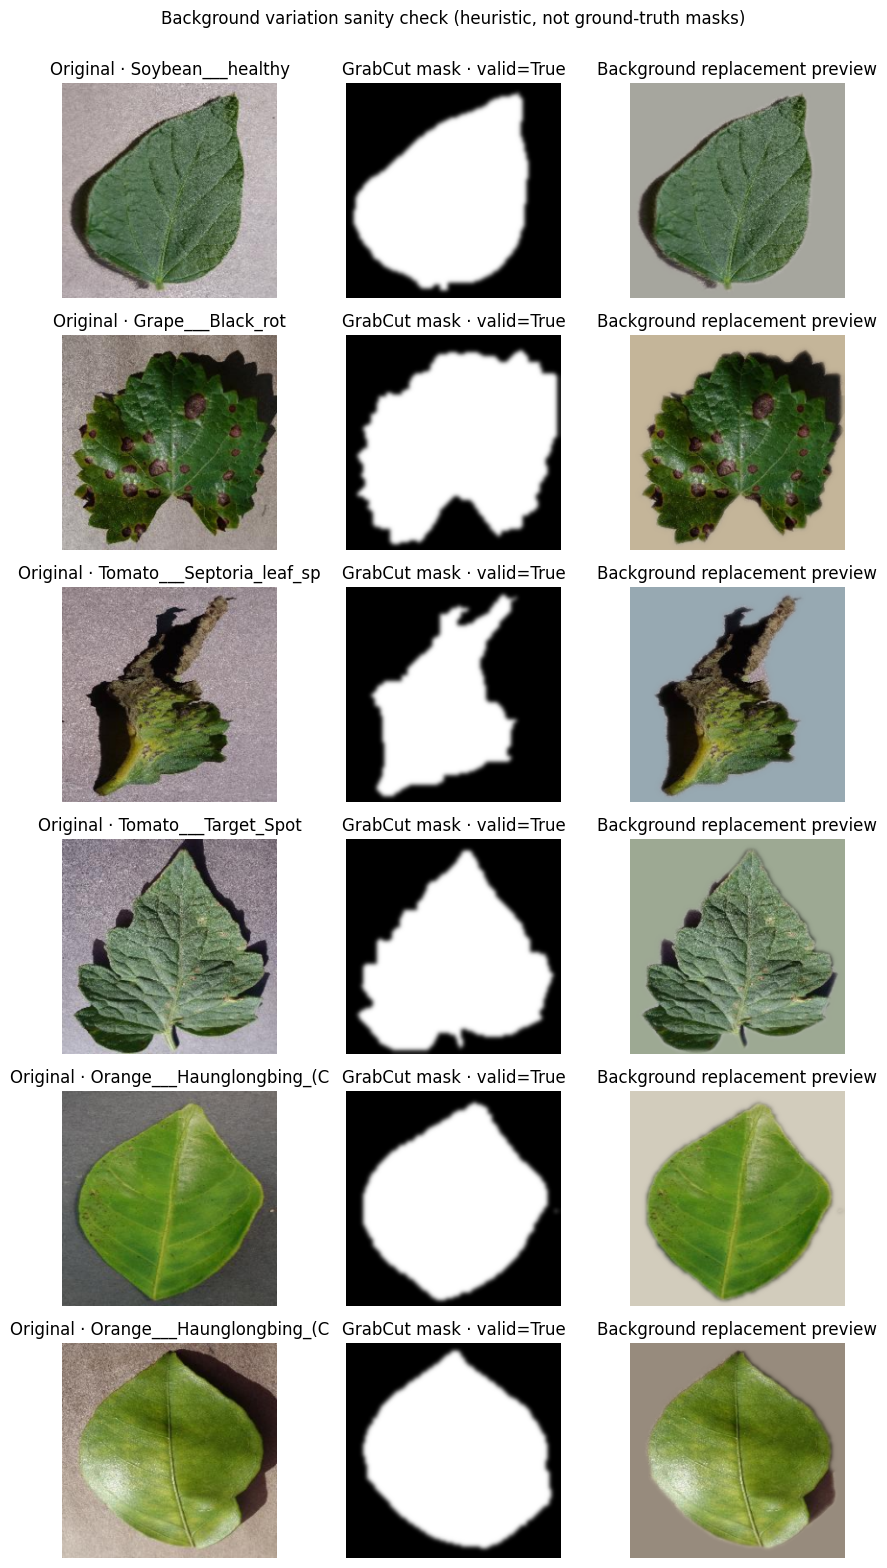

GrabCut preflight valid on 6/6 preview images. Inspect the shown masks before trusting the background candidate.


In [5]:
# Pre-cache smoke checks: exercise every GPU augmentation branch and the GrabCut mask estimator.
_smoke_images = torch.randint(0, 256, (2, 48, 48, 3), dtype=torch.uint8)
_smoke_alpha = torch.full((2, BACKGROUND_MASK_SIZE, BACKGROUND_MASK_SIZE), 255, dtype=torch.uint8)
_smoke_alpha[:, 8:104, 8:104] = 0
for _cfg in CONFIGS:
    _kwargs = {"probabilities": _cfg["probabilities"]}
    if _cfg["probabilities"]["p_background"] > 0:
        _kwargs["background_alpha_uint8"] = _smoke_alpha
    _smoke_output = augment_batch_gpu(_smoke_images, _cfg["mode"], device=DEVICE, **_kwargs)
    assert tuple(_smoke_output.shape) == (2, 3, 48, 48), (_cfg["name"], _smoke_output.shape)
    assert torch.isfinite(_smoke_output).all(), f"Non-finite output in {_cfg['name']}"
print(f"Passed: all {len(CONFIGS)} recipes return finite tensors with expected shapes and valid probabilities.")

# Run GrabCut on a few actual training files now, before the multi-GiB image cache is built.
# This catches OpenCV/API problems early and gives a quick visual quality check.
_preview_rows = np.linspace(0, len(train_df) - 1, min(6, len(train_df)), dtype=int)
_preview_originals, _preview_alphas, _preview_valid = [], [], []
for _row_i in _preview_rows:
    with Image.open(train_df.iloc[int(_row_i)]["resolved_image_path"]) as _im:
        _rgb = np.asarray(_im.convert("RGB").resize((IMG_SIZE, IMG_SIZE), Image.Resampling.BILINEAR), dtype=np.uint8)
    _alpha, _ok = estimate_foreground_alpha_from_rgb(_rgb)
    _preview_originals.append(_rgb)
    _preview_alphas.append(cv2.resize(_alpha, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_LINEAR))
    _preview_valid.append(_ok)

fig, axes = plt.subplots(len(_preview_rows), 3, figsize=(9, 2.6 * len(_preview_rows)))
if len(_preview_rows) == 1:
    axes = np.expand_dims(axes, 0)
for _i, (_rgb, _alpha) in enumerate(zip(_preview_originals, _preview_alphas)):
    _palette = np.asarray(BACKGROUND_PALETTE, dtype=np.uint8)
    _colour = _palette[_i % len(_palette)]
    _fake_bg = np.broadcast_to(_colour[None, None, :], _rgb.shape)
    _composite = ((_rgb.astype(np.float32) * (_alpha[..., None] / 255.0))
                  + (_fake_bg.astype(np.float32) * (1 - _alpha[..., None] / 255.0))).clip(0, 255).astype(np.uint8)
    axes[_i, 0].imshow(_rgb); axes[_i, 0].set_title(f"Original · {train_df.iloc[int(_preview_rows[_i])]['class'][:25]}")
    axes[_i, 1].imshow(_alpha, cmap="gray", vmin=0, vmax=255); axes[_i, 1].set_title(f"GrabCut mask · valid={_preview_valid[_i]}")
    axes[_i, 2].imshow(_composite); axes[_i, 2].set_title("Background replacement preview")
    for _ax in axes[_i]: _ax.axis("off")
fig.suptitle("Background variation sanity check (heuristic, not ground-truth masks)", y=1.002)
fig.tight_layout()
if IN_NOTEBOOK: plt.show()
plt.close(fig)
print(f"GrabCut preflight valid on {sum(_preview_valid)}/{len(_preview_valid)} preview images. Inspect the shown masks before trusting the background candidate.")
if sum(_preview_valid) == 0:
    print("WARNING: no preview mask looked valid; background candidate will mostly fall back to original backgrounds. Check the segmentation heuristic before interpreting it.")
del _smoke_images, _smoke_alpha, _smoke_output
if DEVICE.type == "cuda": torch.cuda.empty_cache()


## 3. Decode/resize training + validation images once

The image cache contains all train and validation RGB images as `uint8` at 224×224 (about **6.4 GiB**). A separate resumable foreground-alpha cache will contain training masks only (about **0.44 GiB** at 112×112). Both are stored under the study cache folder, visible in Kaggle's Output panel; they are not placed in the results ZIP.

The image cache uses parallel decoding/resizing, chunk-level flushes and a per-row progress bitmap. A partial cache can resume in the **same Kaggle session** if its partial files remain present. Restarting a session may remove its working files.


In [6]:
from concurrent.futures import ThreadPoolExecutor

train_val_df = pd.concat([train_df, val_df], ignore_index=True)
cache_digest_source = (
    train_val_df["split"].astype(str) + "\t" + train_val_df["relative_path"].astype(str)
    + "\t" + train_val_df["class"].astype(str)
).str.cat(sep="\n")
CACHE_FINGERPRINT = hashlib.sha256(f"{IMG_SIZE}\n{cache_digest_source}".encode("utf-8")).hexdigest()
_cache_override = os.environ.get("TERRAVISTA_CACHE_DIR", "").strip()
_kaggle_temp_cache = Path("/kaggle/temp/terravista_cache")
_default_cache = BASE_OUTPUT_DIR / "cache"
if _cache_override:
    CACHE_DIR = Path(_cache_override).expanduser()
else:
    # Reuse an existing legacy /kaggle/temp cache if it is already complete; otherwise
    # keep newly built cache visible under /kaggle/working in the Output panel.
    _legacy_candidate = _kaggle_temp_cache / f"plantvillage_train_val_{IMG_SIZE}_{CACHE_FINGERPRINT[:12]}.npy"
    _working_candidate = _default_cache / f"plantvillage_train_val_{IMG_SIZE}_{CACHE_FINGERPRINT[:12]}.npy"
    CACHE_DIR = _kaggle_temp_cache if _legacy_candidate.is_file() and not _working_candidate.is_file() else _default_cache
CACHE_DIR.mkdir(parents=True, exist_ok=True)
print("Cache directory:", CACHE_DIR)
CACHE_PATH = CACHE_DIR / f"plantvillage_train_val_{IMG_SIZE}_{CACHE_FINGERPRINT[:12]}.npy"
CACHE_META_PATH = CACHE_PATH.with_suffix(".json")
CACHE_PARTIAL_PATH = CACHE_PATH.with_name(CACHE_PATH.stem + ".partial.npy")
CACHE_PROGRESS_PATH = CACHE_PATH.with_name(CACHE_PATH.stem + ".progress.npy")
CACHE_SHAPE = (len(train_val_df), IMG_SIZE, IMG_SIZE, 3)
CACHE_ESTIMATED_BYTES = int(np.prod(CACHE_SHAPE))
CACHE_WORKERS = max(2, min(8, os.cpu_count() or 4, int(os.environ.get("TERRAVISTA_CACHE_WORKERS", "8"))))
CACHE_CHUNK_SIZE = max(64, CACHE_WORKERS * 32)


def _decode_resize_cache_item(item):
    """Thread worker: open and resize one RGB image; return (row index, uint8 array)."""
    row_index, image_path = item
    resampling = Image.Resampling.BILINEAR if hasattr(Image, "Resampling") else Image.BILINEAR
    try:
        with Image.open(image_path) as src:
            rgb = src.convert("RGB").resize((IMG_SIZE, IMG_SIZE), resampling)
            arr = np.asarray(rgb, dtype=np.uint8)
        if arr.shape != (IMG_SIZE, IMG_SIZE, 3):
            raise ValueError(f"Unexpected resized shape {arr.shape}")
        return int(row_index), arr
    except Exception as exc:
        raise RuntimeError(f"Failed to decode image at row {row_index}: {image_path}") from exc


cache_is_valid = False
if CACHE_PATH.is_file():
    try:
        cached = np.load(CACHE_PATH, mmap_mode="r")
        shape_and_dtype_ok = tuple(cached.shape) == CACHE_SHAPE and cached.dtype == np.uint8
        if CACHE_META_PATH.is_file():
            cache_meta = json.loads(CACHE_META_PATH.read_text())
            cache_is_valid = (
                cache_meta.get("fingerprint") == CACHE_FINGERPRINT and shape_and_dtype_ok
            )
        else:
            # The final filename contains this data/split fingerprint. Promotion only
            # happens after every row is written, so a complete final .npy without its
            # sidecar is recoverable after an interruption between the two file moves.
            cache_is_valid = shape_and_dtype_ok
            if cache_is_valid:
                CACHE_META_PATH.write_text(json.dumps({
                    "fingerprint": CACHE_FINGERPRINT,
                    "shape": CACHE_SHAPE,
                    "dtype": "uint8",
                    "image_size": IMG_SIZE,
                    "rows": len(train_val_df),
                    "source": "train + validation rows only",
                    "recovered_metadata": True,
                }, indent=2))
        del cached
    except Exception:
        cache_is_valid = False

if cache_is_valid:
    print("Reusing complete decoded image cache:", CACHE_PATH)
else:
    # Reuse incomplete work after a cell error or runtime interruption. A row is
    # marked done only after the resized bytes have been written to the memmap.
    partial_valid = False
    if CACHE_PARTIAL_PATH.is_file() and CACHE_PROGRESS_PATH.is_file():
        try:
            partial = np.load(CACHE_PARTIAL_PATH, mmap_mode="r+")
            progress = np.load(CACHE_PROGRESS_PATH, mmap_mode="r+")
            partial_valid = (
                tuple(partial.shape) == CACHE_SHAPE
                and partial.dtype == np.uint8
                and tuple(progress.shape) == (CACHE_SHAPE[0],)
                and progress.dtype == np.uint8
            )
            if partial_valid:
                cache = partial
                done = progress
            else:
                del partial, progress
        except Exception:
            partial_valid = False

    if not partial_valid:
        CACHE_PARTIAL_PATH.unlink(missing_ok=True)
        CACHE_PROGRESS_PATH.unlink(missing_ok=True)
        free_bytes = shutil.disk_usage(CACHE_DIR).free
        estimated_mask_bytes = int(len(train_df) * BACKGROUND_MASK_SIZE * BACKGROUND_MASK_SIZE)
        required_bytes = CACHE_ESTIMATED_BYTES + estimated_mask_bytes + 512 * 1024 * 1024
        if free_bytes < required_bytes:
            raise OSError(
                f"Not enough free working storage for the image cache. Need about "
                f"about {(CACHE_ESTIMATED_BYTES + estimated_mask_bytes) / (1024**3):.2f} GiB for images and masks plus a safety margin; "
                f"free={free_bytes / (1024**3):.2f} GiB. Set TERRAVISTA_OUTPUT_DIR "
                "to a drive with more space."
            )
        print(f"Starting image-cache build: {len(train_val_df):,} train/validation images; "
              f"estimated image cache {CACHE_ESTIMATED_BYTES / (1024**3):.2f} GiB. "
              f"A separate ~{estimated_mask_bytes / (1024**3):.2f} GiB training-mask cache is created next.")
        cache = np.lib.format.open_memmap(
            CACHE_PARTIAL_PATH, mode="w+", dtype=np.uint8, shape=CACHE_SHAPE
        )
        done = np.lib.format.open_memmap(
            CACHE_PROGRESS_PATH, mode="w+", dtype=np.uint8, shape=(CACHE_SHAPE[0],)
        )
        done[:] = 0
        cache.flush()
        done.flush()

    completed_before = int(np.asarray(done).sum())
    remaining = np.flatnonzero(np.asarray(done) == 0)
    print(f"Cache workers: {CACHE_WORKERS}; chunk size: {CACHE_CHUNK_SIZE}; "
          f"resuming {completed_before:,}/{len(train_val_df):,} cached rows.")
    paths = train_val_df["resolved_image_path"].astype(str).to_numpy()
    progress_bar = tqdm(total=len(train_val_df), initial=completed_before,
                        desc="Parallel decode + resize", mininterval=2)
    try:
        with ThreadPoolExecutor(max_workers=CACHE_WORKERS) as pool:
            for start in range(0, len(remaining), CACHE_CHUNK_SIZE):
                indices = remaining[start:start + CACHE_CHUNK_SIZE]
                tasks = [(int(i), paths[int(i)]) for i in indices]
                for row_index, arr in pool.map(_decode_resize_cache_item, tasks):
                    cache[row_index] = arr
                    done[row_index] = 1
                # Frequent flushes make the cache resumable without losing a full pass.
                cache.flush()
                done.flush()
                progress_bar.update(len(indices))
    except Exception:
        cache.flush()
        done.flush()
        progress_bar.close()
        del cache, done
        raise
    progress_bar.close()
    cache.flush()
    done.flush()
    if int(np.asarray(done).sum()) != len(train_val_df):
        raise RuntimeError("Cache build did not finish all train/validation rows; rerun this cell to resume.")
    del cache, done

    # Write metadata before promotion. If the process is interrupted, the partial
    # array and row bitmap remain available for resuming.
    meta_tmp = CACHE_META_PATH.with_name(CACHE_META_PATH.name + ".tmp")
    meta_tmp.write_text(json.dumps({
        "fingerprint": CACHE_FINGERPRINT,
        "shape": CACHE_SHAPE,
        "dtype": "uint8",
        "image_size": IMG_SIZE,
        "rows": len(train_val_df),
        "source": "train + validation rows only",
        "cache_workers": CACHE_WORKERS,
    }, indent=2))
    os.replace(CACHE_PARTIAL_PATH, CACHE_PATH)
    os.replace(meta_tmp, CACHE_META_PATH)
    CACHE_PROGRESS_PATH.unlink(missing_ok=True)
    print("Saved complete cache:", CACHE_PATH)

TRAIN_POSITIONS = np.arange(len(train_df), dtype=np.int64)
VAL_POSITIONS = np.arange(len(train_df), len(train_df) + len(val_df), dtype=np.int64)
TRAIN_LABEL_IDS = train_df["class"].astype(str).map(CLASS_TO_IDX).to_numpy(dtype=np.int64)
VAL_LABEL_IDS = val_df["class"].astype(str).map(CLASS_TO_IDX).to_numpy(dtype=np.int64)
print("Cache ready. Train/validation rows:", len(TRAIN_POSITIONS), "/", len(VAL_POSITIONS))
print("Only training and validation image paths are used; no test images or test metrics are loaded.")


Cache directory: /kaggle/working/terravista_augmentation_validation_study/cache
Starting image-cache build: 45,727 train/validation images; estimated image cache 6.41 GiB. A separate ~0.44 GiB training-mask cache is created next.
Cache workers: 4; chunk size: 128; resuming 0/45,727 cached rows.


Parallel decode + resize:   0%|          | 0/45727 [00:00<?, ?it/s]

Saved complete cache: /kaggle/working/terravista_augmentation_validation_study/cache/plantvillage_train_val_224_9fb74edc1aef.npy
Cache ready. Train/validation rows: 37751 / 7976
Only training and validation image paths are used; no test images or test metrics are loaded.


## 4. Cache training foreground masks for background variation (training only)

This cell computes each training image's heuristic GrabCut alpha mask once at 112×112, stores it as a resumable `uint8` memmap, and shows a representative preview. It does **not** build masks for validation or test images. Invalid/implausible masks are stored as fully foreground so those examples retain their original backgrounds.


Foreground-mask cache: 37,751 training images; size ~0.44 GiB; workers=4; resuming 0/37,751.


Training-only GrabCut masks:   0%|          | 0/37751 [00:00<?, ?it/s]

Saved training mask cache: /kaggle/working/terravista_augmentation_validation_study/cache/foreground_alpha_train_112_c95c6139a9c9.npy
Training masks ready: 37,751; fully-foreground/no-op masks: 0 (0.0%).


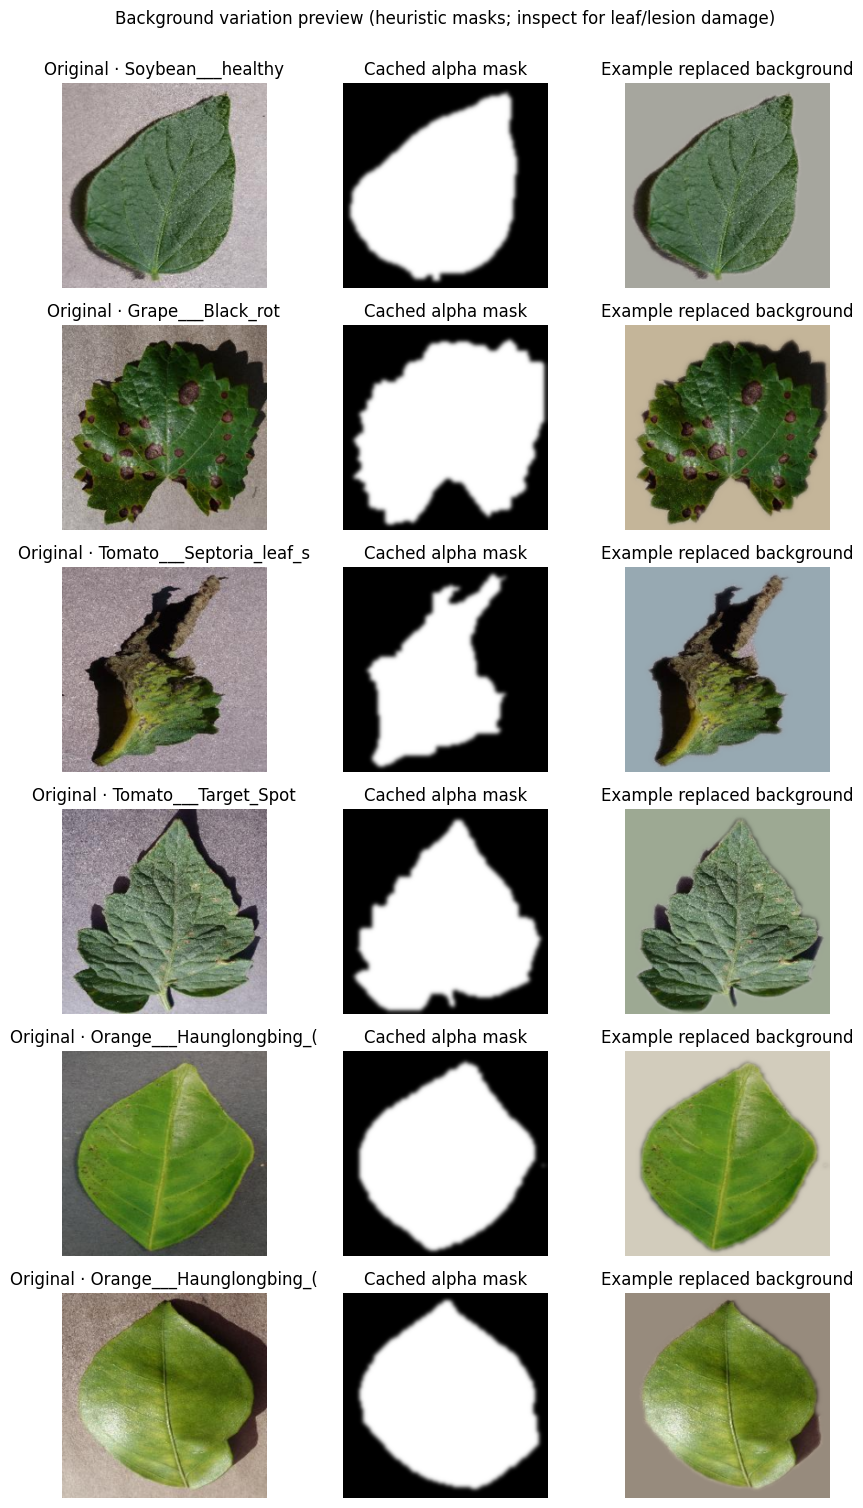

Only training images have a background-mask cache. Validation stays deterministic; test images are never used.


In [7]:
# Resumable, train-only mask cache. The RGB image cache is read via mmap and not copied wholesale into RAM.
MASK_CACHE_FINGERPRINT = hashlib.sha256(
    f"{CACHE_FINGERPRINT}\n{BACKGROUND_MASK_CACHE_VERSION}\n{BACKGROUND_MASK_SIZE}".encode("utf-8")
).hexdigest()
BACKGROUND_MASK_CACHE_PATH = CACHE_DIR / f"foreground_alpha_train_{BACKGROUND_MASK_SIZE}_{MASK_CACHE_FINGERPRINT[:12]}.npy"
BACKGROUND_MASK_META_PATH = BACKGROUND_MASK_CACHE_PATH.with_suffix(".json")
BACKGROUND_MASK_PARTIAL_PATH = BACKGROUND_MASK_CACHE_PATH.with_name(BACKGROUND_MASK_CACHE_PATH.stem + ".partial.npy")
BACKGROUND_MASK_PROGRESS_PATH = BACKGROUND_MASK_CACHE_PATH.with_name(BACKGROUND_MASK_CACHE_PATH.stem + ".progress.npy")
BACKGROUND_MASK_SHAPE = (len(train_df), BACKGROUND_MASK_SIZE, BACKGROUND_MASK_SIZE)
BACKGROUND_MASK_ESTIMATED_BYTES = int(np.prod(BACKGROUND_MASK_SHAPE))

mask_cache_is_valid = False
if BACKGROUND_MASK_CACHE_PATH.is_file():
    try:
        _mask_cached = np.load(BACKGROUND_MASK_CACHE_PATH, mmap_mode="r")
        _mask_shape_ok = tuple(_mask_cached.shape) == BACKGROUND_MASK_SHAPE and _mask_cached.dtype == np.uint8
        if BACKGROUND_MASK_META_PATH.is_file():
            _mask_meta = json.loads(BACKGROUND_MASK_META_PATH.read_text())
            mask_cache_is_valid = _mask_meta.get("fingerprint") == MASK_CACHE_FINGERPRINT and _mask_shape_ok
        else:
            mask_cache_is_valid = _mask_shape_ok
            if mask_cache_is_valid:
                BACKGROUND_MASK_META_PATH.write_text(json.dumps({
                    "fingerprint": MASK_CACHE_FINGERPRINT,
                    "shape": BACKGROUND_MASK_SHAPE,
                    "dtype": "uint8",
                    "mask_size": BACKGROUND_MASK_SIZE,
                    "rows": len(train_df),
                    "algorithm": BACKGROUND_MASK_CACHE_VERSION,
                    "source": "training images only",
                    "recovered_metadata": True,
                }, indent=2))
        del _mask_cached
    except Exception:
        mask_cache_is_valid = False

if mask_cache_is_valid:
    print("Reusing complete training foreground-mask cache:", BACKGROUND_MASK_CACHE_PATH)
else:
    _partial_valid = False
    if BACKGROUND_MASK_PARTIAL_PATH.is_file() and BACKGROUND_MASK_PROGRESS_PATH.is_file():
        try:
            _partial_masks = np.load(BACKGROUND_MASK_PARTIAL_PATH, mmap_mode="r+")
            _mask_done = np.load(BACKGROUND_MASK_PROGRESS_PATH, mmap_mode="r+")
            _partial_valid = (
                tuple(_partial_masks.shape) == BACKGROUND_MASK_SHAPE and _partial_masks.dtype == np.uint8
                and tuple(_mask_done.shape) == (len(train_df),) and _mask_done.dtype == np.uint8
            )
            if _partial_valid:
                _mask_cache, _mask_progress = _partial_masks, _mask_done
            else:
                del _partial_masks, _mask_done
        except Exception:
            _partial_valid = False
    if not _partial_valid:
        BACKGROUND_MASK_PARTIAL_PATH.unlink(missing_ok=True)
        BACKGROUND_MASK_PROGRESS_PATH.unlink(missing_ok=True)
        _free_mask_bytes = shutil.disk_usage(CACHE_DIR).free
        _mask_required_bytes = BACKGROUND_MASK_ESTIMATED_BYTES + 128 * 1024 * 1024
        if _free_mask_bytes < _mask_required_bytes:
            raise OSError(
                f"Not enough space for the ~{BACKGROUND_MASK_ESTIMATED_BYTES / (1024**3):.2f} GiB training mask cache; "
                f"free space={_free_mask_bytes / (1024**3):.2f} GiB. Free space or set TERRAVISTA_CACHE_DIR."
            )
        _mask_cache = np.lib.format.open_memmap(
            BACKGROUND_MASK_PARTIAL_PATH, mode="w+", dtype=np.uint8, shape=BACKGROUND_MASK_SHAPE
        )
        _mask_progress = np.lib.format.open_memmap(
            BACKGROUND_MASK_PROGRESS_PATH, mode="w+", dtype=np.uint8, shape=(len(train_df),)
        )
        _mask_progress[:] = 0
        _mask_cache[:] = 255  # safe fallback for rows not completed yet
        _mask_cache.flush(); _mask_progress.flush()

    _image_cache_read = np.load(CACHE_PATH, mmap_mode="r")
    _mask_completed_before = int(np.asarray(_mask_progress).sum())
    _mask_remaining = np.flatnonzero(np.asarray(_mask_progress) == 0)
    _mask_chunk_size = max(16, min(64, CACHE_WORKERS * 8))
    print(f"Foreground-mask cache: {len(train_df):,} training images; size ~{BACKGROUND_MASK_ESTIMATED_BYTES / (1024**3):.2f} GiB; "
          f"workers={CACHE_WORKERS}; resuming {_mask_completed_before:,}/{len(train_df):,}.")

    def _mask_worker(row_index):
        _rgb = np.asarray(_image_cache_read[int(row_index)])
        _alpha, _valid = estimate_foreground_alpha_from_rgb(_rgb, output_size=BACKGROUND_MASK_SIZE)
        return int(row_index), _alpha

    _mask_bar = tqdm(total=len(train_df), initial=_mask_completed_before, desc="Training-only GrabCut masks", mininterval=2)
    try:
        with ThreadPoolExecutor(max_workers=CACHE_WORKERS) as _mask_pool:
            for _start in range(0, len(_mask_remaining), _mask_chunk_size):
                _indices = _mask_remaining[_start:_start + _mask_chunk_size]
                for _row_idx, _alpha in _mask_pool.map(_mask_worker, _indices):
                    _mask_cache[_row_idx] = _alpha
                    _mask_progress[_row_idx] = 1
                _mask_cache.flush(); _mask_progress.flush()
                _mask_bar.update(len(_indices))
    except Exception:
        _mask_cache.flush(); _mask_progress.flush(); _mask_bar.close()
        del _mask_cache, _mask_progress, _image_cache_read
        raise
    _mask_bar.close()
    _mask_cache.flush(); _mask_progress.flush()
    if int(np.asarray(_mask_progress).sum()) != len(train_df):
        del _mask_cache, _mask_progress, _image_cache_read
        raise RuntimeError("Training-mask cache is incomplete; rerun this cell to resume.")
    del _mask_cache, _mask_progress, _image_cache_read
    _mask_meta_tmp = BACKGROUND_MASK_META_PATH.with_name(BACKGROUND_MASK_META_PATH.name + ".tmp")
    _mask_meta_tmp.write_text(json.dumps({
        "fingerprint": MASK_CACHE_FINGERPRINT,
        "shape": BACKGROUND_MASK_SHAPE,
        "dtype": "uint8",
        "mask_size": BACKGROUND_MASK_SIZE,
        "rows": len(train_df),
        "algorithm": BACKGROUND_MASK_CACHE_VERSION,
        "source": "training images only",
        "workers": CACHE_WORKERS,
    }, indent=2))
    os.replace(BACKGROUND_MASK_PARTIAL_PATH, BACKGROUND_MASK_CACHE_PATH)
    os.replace(_mask_meta_tmp, BACKGROUND_MASK_META_PATH)
    BACKGROUND_MASK_PROGRESS_PATH.unlink(missing_ok=True)
    print("Saved training mask cache:", BACKGROUND_MASK_CACHE_PATH)

# Report fallback masks and show some of the exact cached masks/composites.
_background_masks_read = np.load(BACKGROUND_MASK_CACHE_PATH, mmap_mode="r")
_fallback_count = int(np.all(np.asarray(_background_masks_read) == 255, axis=(1, 2)).sum())
print(f"Training masks ready: {len(train_df):,}; fully-foreground/no-op masks: {_fallback_count:,} ({_fallback_count / max(len(train_df),1):.1%}).")
_preview_indices = np.linspace(0, len(train_df) - 1, min(6, len(train_df)), dtype=int)
_fig, _axes = plt.subplots(len(_preview_indices), 3, figsize=(9, 2.5 * len(_preview_indices)))
if len(_preview_indices) == 1: _axes = np.expand_dims(_axes, 0)
for _i, _idx in enumerate(_preview_indices):
    _rgb = np.asarray(np.load(CACHE_PATH, mmap_mode="r")[_idx])
    _alpha = cv2.resize(np.asarray(_background_masks_read[_idx]), (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_LINEAR)
    _palette = np.asarray(BACKGROUND_PALETTE, dtype=np.uint8)
    _color = _palette[_i % len(_palette)]
    _bg = np.broadcast_to(_color[None, None, :], _rgb.shape)
    _a = _alpha[..., None].astype(np.float32) / 255.0
    _composite = (_rgb.astype(np.float32) * _a + _bg.astype(np.float32) * (1.0 - _a)).clip(0,255).astype(np.uint8)
    _axes[_i,0].imshow(_rgb); _axes[_i,0].set_title(f"Original · {train_df.iloc[int(_idx)]['class'][:24]}")
    _axes[_i,1].imshow(_alpha, cmap="gray", vmin=0, vmax=255); _axes[_i,1].set_title("Cached alpha mask")
    _axes[_i,2].imshow(_composite); _axes[_i,2].set_title("Example replaced background")
    for _ax in _axes[_i]: _ax.axis("off")
_fig.suptitle("Background variation preview (heuristic masks; inspect for leaf/lesion damage)", y=1.002)
_fig.tight_layout()
if IN_NOTEBOOK: plt.show()
plt.close(_fig)
del _background_masks_read
print("Only training images have a background-mask cache. Validation stays deterministic; test images are never used.")


## 5. Cached dataset, ResNet-50, and full validation metrics

The data loader memory-maps the decoded image cache. Only the fifth background configuration also reads its matching cached alpha mask. ResNet-50 starts from the standard pretrained weights and all backbone layers remain trainable.

In [8]:
class CachedImageDataset(Dataset):
    def __init__(self, cache_path, positions, label_ids, include_background_masks=False):
        self.cache_path = str(cache_path)
        self.positions = np.asarray(positions, dtype=np.int64)
        self.label_ids = np.asarray(label_ids, dtype=np.int64)
        self.include_background_masks = bool(include_background_masks)
        self._cache = None
        self._mask_cache = None

    def __len__(self):
        return len(self.positions)

    def __getitem__(self, index):
        if self._cache is None:
            self._cache = np.load(self.cache_path, mmap_mode="r")
        cache_position = int(self.positions[index])
        image = np.array(self._cache[cache_position], copy=True)
        label = int(self.label_ids[index])
        if self.include_background_masks:
            if self._mask_cache is None:
                self._mask_cache = np.load(str(BACKGROUND_MASK_CACHE_PATH), mmap_mode="r")
            # Background masks are indexed by training position, not train+validation position.
            mask = np.array(self._mask_cache[cache_position], copy=True)
            return torch.from_numpy(image), label, torch.from_numpy(mask)
        return torch.from_numpy(image), label


def _worker_init(worker_id):
    torch.set_num_threads(1)
    worker_seed = torch.initial_seed() % (2**32)
    np.random.seed(worker_seed)
    random.seed(worker_seed)


def make_loader(positions, labels, *, train, seed, include_background_masks=False):
    if include_background_masks and not train:
        raise ValueError("Background masks are supplied only to the training loader.")
    generator = torch.Generator()
    generator.manual_seed(int(seed))
    kwargs = dict(
        dataset=CachedImageDataset(CACHE_PATH, positions, labels, include_background_masks=include_background_masks),
        batch_size=TRAIN_BATCH_SIZE if train else EVAL_BATCH_SIZE,
        shuffle=train,
        num_workers=NUM_WORKERS,
        pin_memory=True,
        generator=generator if train else None,
        worker_init_fn=_worker_init,
    )
    if NUM_WORKERS > 0:
        kwargs.update(persistent_workers=True, prefetch_factor=PREFETCH_FACTOR)
    loader = DataLoader(**kwargs)
    return loader


def reset_random_seeds(seed):
    random.seed(int(seed))
    np.random.seed(int(seed))
    torch.manual_seed(int(seed))
    torch.cuda.manual_seed_all(int(seed))


def build_resnet50():
    weights = torchvision.models.ResNet50_Weights.DEFAULT
    model = torchvision.models.resnet50(weights=weights)
    model.fc = nn.Linear(model.fc.in_features, NUM_CLASSES)
    # All ResNet-50 layers remain trainable for this fine-tuning study.
    for parameter in model.parameters():
        parameter.requires_grad = True
    return model.to(DEVICE)


def make_optimizer(model):
    backbone_params = [p for n, p in model.named_parameters() if not n.startswith("fc.")]
    return torch.optim.AdamW(
        [
            {"params": backbone_params, "lr": BACKBONE_LR},
            {"params": model.fc.parameters(), "lr": CLASSIFIER_LR},
        ],
        weight_decay=WEIGHT_DECAY,
    )


def new_grad_scaler():
    try:
        return torch.amp.GradScaler("cuda", enabled=USE_AMP)
    except (AttributeError, TypeError):
        return torch.cuda.amp.GradScaler(enabled=USE_AMP)


def normalize_validation_batch(images_uint8):
    return augment_batch_gpu(images_uint8, "none", device=DEVICE)


def score_predictions(y_true, y_pred):
    labels = list(range(NUM_CLASSES))
    return {
        "val_accuracy": float(accuracy_score(y_true, y_pred)),
        "val_macro_precision": float(precision_score(y_true, y_pred, labels=labels, average="macro", zero_division=0)),
        "val_macro_recall": float(recall_score(y_true, y_pred, labels=labels, average="macro", zero_division=0)),
        "val_macro_f1": float(f1_score(y_true, y_pred, labels=labels, average="macro", zero_division=0)),
        "val_weighted_precision": float(precision_score(y_true, y_pred, labels=labels, average="weighted", zero_division=0)),
        "val_weighted_recall": float(recall_score(y_true, y_pred, labels=labels, average="weighted", zero_division=0)),
        "val_weighted_f1": float(f1_score(y_true, y_pred, labels=labels, average="weighted", zero_division=0)),
    }


@torch.inference_mode()
def evaluate_model(model, loader):
    model.eval()
    loss_fn = nn.CrossEntropyLoss()
    true_all, pred_all = [], []
    loss_total, n_total = 0.0, 0
    for images_uint8, labels_cpu in loader:
        images = normalize_validation_batch(images_uint8)
        labels = labels_cpu.to(DEVICE, non_blocking=True)
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
            logits = model(images)
            loss = loss_fn(logits, labels)
        n = int(labels.size(0))
        loss_total += float(loss.item()) * n
        n_total += n
        true_all.append(labels.cpu().numpy())
        pred_all.append(logits.argmax(dim=1).cpu().numpy())
    y_true = np.concatenate(true_all)
    y_pred = np.concatenate(pred_all)
    metrics = score_predictions(y_true, y_pred)
    metrics["val_loss"] = float(loss_total / max(n_total, 1))
    metrics["y_true"] = y_true
    metrics["y_pred"] = y_pred
    return metrics


def train_one_epoch(model, loader, optimizer, scaler, config):
    model.train()
    loss_fn = nn.CrossEntropyLoss()
    loss_total = torch.zeros((), device=DEVICE, dtype=torch.float64)
    correct = torch.zeros((), device=DEVICE, dtype=torch.long)
    n_total = 0
    mode = config["mode"]
    progress = tqdm(loader, desc=f"Train ({config['name']})", leave=False, mininterval=2)
    for batch in progress:
        if len(batch) == 3:
            images_uint8, labels_cpu, background_alpha_uint8 = batch
        else:
            images_uint8, labels_cpu = batch
            background_alpha_uint8 = None
        images = augment_batch_gpu(
            images_uint8,
            mode,
            device=DEVICE,
            probabilities=config["probabilities"],
            background_alpha_uint8=background_alpha_uint8,
            rotation_degrees=ROTATION_DEGREES,
            brightness_range=BRIGHTNESS_RANGE,
            contrast_range=CONTRAST_RANGE,
            saturation_range=SATURATION_RANGE,
            hue_strength=HUE_STRENGTH,
            blur_kernel_size=BLUR_KERNEL_SIZE,
            sensor_noise_std=SENSOR_NOISE_STD,
            cutout_max_area=CUTOUT_MAX_AREA,
        )
        labels = labels_cpu.to(DEVICE, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
            logits = model(images)
            loss = loss_fn(logits, labels)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        n = int(labels.size(0))
        loss_total += loss.detach().double() * n
        correct += (logits.detach().argmax(1) == labels).sum()
        n_total += n
    return {
        "train_loss": float(loss_total.item() / max(n_total, 1)),
        "train_accuracy": float(correct.item() / max(n_total, 1)),
    }

print("Model: pretrained ResNet-50; all layers trainable.")
print("Validation loader: deterministic resize cache + ImageNet normalization only.")


Model: pretrained ResNet-50; all layers trainable.
Validation loader: deterministic resize cache + ImageNet normalization only.


## 6. Three-seed experiment, per-epoch checkpointing, and resume support

Every run starts from the same ImageNet pretrained ResNet-50 weights and trains on the **entire training split**. Every epoch is scored on all validation images without random transforms. The fifth candidate uses cached training masks and GPU-generated backgrounds; it does not run GrabCut inside the training loop.

In [9]:
METRICS_DIR = BASE_OUTPUT_DIR / "runs"
METRICS_DIR.mkdir(parents=True, exist_ok=True)
SIGNATURE_PAYLOAD = {
    "study_version": STUDY_VERSION,
    "cache_fingerprint": CACHE_FINGERPRINT,
    "background_mask_fingerprint": MASK_CACHE_FINGERPRINT,
    "background_mask_size": BACKGROUND_MASK_SIZE,
    "image_size": IMG_SIZE,
    "seeds": SEEDS,
    "search_epochs": SEARCH_EPOCHS,
    "train_batch_size": TRAIN_BATCH_SIZE,
    "eval_batch_size": EVAL_BATCH_SIZE,
    "backbone_lr": BACKBONE_LR,
    "classifier_lr": CLASSIFIER_LR,
    "weight_decay": WEIGHT_DECAY,
    "rotation_degrees": ROTATION_DEGREES,
    "brightness_range": BRIGHTNESS_RANGE,
    "contrast_range": CONTRAST_RANGE,
    "saturation_range": SATURATION_RANGE,
    "hue_strength": HUE_STRENGTH,
    "blur_kernel_size": BLUR_KERNEL_SIZE,
    "sensor_noise_std": SENSOR_NOISE_STD,
    "cutout_max_area": CUTOUT_MAX_AREA,
    "background_mask_algorithm": BACKGROUND_MASK_CACHE_VERSION,
    "configs": CONFIGS,
}
RUN_SIGNATURE = hashlib.sha256(json.dumps(SIGNATURE_PAYLOAD, sort_keys=True).encode()).hexdigest()[:12]
RUN_DIR = METRICS_DIR / f"{STUDY_VERSION}_{RUN_SIGNATURE}"
CHECKPOINT_DIR = RUN_DIR / "checkpoints"
HISTORY_DIR = RUN_DIR / "histories"
PREDICTION_DIR = RUN_DIR / "validation_predictions"
PLOT_DIR = RUN_DIR / "plots"
for folder in [RUN_DIR, CHECKPOINT_DIR, HISTORY_DIR, PREDICTION_DIR, PLOT_DIR]:
    folder.mkdir(parents=True, exist_ok=True)
CONFIG_JSON_DIR = RUN_DIR / "augmentation_configurations"
CONFIG_JSON_DIR.mkdir(parents=True, exist_ok=True)

def _configuration_payload(cfg):
    return {
        "config_name": cfg["name"],
        "description": cfg["description"],
        "mode": cfg["mode"],
        "probabilities": {key: float(cfg["probabilities"][key]) for key in PROBABILITY_KEYS},
        "fixed_transform_strengths": {
            "rotation_max_degrees": ROTATION_DEGREES,
            "brightness_range": list(BRIGHTNESS_RANGE),
            "contrast_range": list(CONTRAST_RANGE),
            "saturation_range": list(SATURATION_RANGE),
            "hue_strength": HUE_STRENGTH,
            "gaussian_blur_kernel_size": BLUR_KERNEL_SIZE,
            "sensor_noise_std_rgb_0_to_1": SENSOR_NOISE_STD,
            "cutout_min_area_fraction": 0.02,
            "cutout_max_area_fraction": CUTOUT_MAX_AREA,
            "background_mask_size": BACKGROUND_MASK_SIZE,
            "background_mask_algorithm": BACKGROUND_MASK_CACHE_VERSION,
        },
        "applied_to_training_only": True,
        "validation_augmentation": "none; resize/cache + ImageNet normalization only",
        "test_split_touched": False,
    }

# Save all five candidate recipes before training starts, so their exact definitions are retained even if a run is interrupted.
all_config_payloads = {cfg["name"]: _configuration_payload(cfg) for cfg in CONFIGS}
(RUN_DIR / "all_augmentation_configurations.json").write_text(json.dumps({
    "study_version": STUDY_VERSION,
    "run_signature": RUN_SIGNATURE,
    "expected_configurations": len(CONFIGS),
    "seeds": SEEDS,
    "epochs_per_run": SEARCH_EPOCHS,
    "configurations": all_config_payloads,
}, indent=2))
for _cfg_name, _payload in all_config_payloads.items():
    (CONFIG_JSON_DIR / f"{_cfg_name}.json").write_text(json.dumps(_payload, indent=2))
RESULTS_CSV = RUN_DIR / "augmentation_seed_results.csv"


def atomic_write_csv(frame, path):
    path = Path(path)
    temp = path.with_name(path.name + ".tmp")
    frame.to_csv(temp, index=False)
    os.replace(temp, path)


def save_summary_row(row):
    if RESULTS_CSV.exists():
        current = pd.read_csv(RESULTS_CSV)
        current = current.loc[~((current["config_name"] == row["config_name"]) & (current["seed"] == row["seed"]))]
        updated = pd.concat([current, pd.DataFrame([row])], ignore_index=True)
    else:
        updated = pd.DataFrame([row])
    order = {cfg["name"]: i for i, cfg in enumerate(CONFIGS)}
    updated["_order"] = updated["config_name"].map(order)
    updated = updated.sort_values(["_order", "seed"]).drop(columns="_order")
    atomic_write_csv(updated, RESULTS_CSV)


def safe_torch_load(path):
    try:
        return torch.load(path, map_location="cpu", weights_only=False)
    except TypeError:
        return torch.load(path, map_location="cpu")


def run_one_configuration(config, seed):
    run_key = f"{config['name']}_seed{seed}"
    checkpoint_path = CHECKPOINT_DIR / f"{run_key}_resume.pt"
    history_path = HISTORY_DIR / f"{run_key}.csv"
    predictions_path = PREDICTION_DIR / f"{run_key}_best.npz"

    reset_random_seeds(seed)
    model = build_resnet50()
    optimizer = make_optimizer(model)
    scaler = new_grad_scaler()
    train_loader = make_loader(
        TRAIN_POSITIONS, TRAIN_LABEL_IDS, train=True, seed=seed,
        include_background_masks=(config["probabilities"]["p_background"] > 0.0),
    )
    val_loader = make_loader(VAL_POSITIONS, VAL_LABEL_IDS, train=False, seed=seed)

    history_rows = []
    best_metrics = None
    best_predictions = None
    start_epoch = 1
    if checkpoint_path.is_file():
        saved = safe_torch_load(checkpoint_path)
        if saved.get("run_signature") == RUN_SIGNATURE and saved.get("config_name") == config["name"] and int(saved.get("seed")) == int(seed):
            model.load_state_dict(saved["model_state"])
            optimizer.load_state_dict(saved["optimizer_state"])
            if saved.get("scaler_state"):
                scaler.load_state_dict(saved["scaler_state"])
            history_rows = saved.get("history_rows", [])
            best_metrics = saved.get("best_metrics")
            best_predictions = saved.get("best_predictions")
            # Restore every RNG plus the shuffle generator so resuming after an epoch
            # follows the same random sequence as an uninterrupted run.
            if saved.get("python_rng_state") is not None:
                random.setstate(saved["python_rng_state"])
            if saved.get("numpy_rng_state") is not None:
                np.random.set_state(saved["numpy_rng_state"])
            if saved.get("torch_rng_state") is not None:
                torch.set_rng_state(saved["torch_rng_state"])
            if saved.get("cuda_rng_state_all") is not None:
                torch.cuda.set_rng_state_all(saved["cuda_rng_state_all"])
            if saved.get("train_loader_generator_state") is not None:
                train_loader.generator.set_state(saved["train_loader_generator_state"])
            start_epoch = int(saved["last_epoch"]) + 1
            print(f"Resuming {run_key} from epoch {start_epoch}.")
        else:
            checkpoint_path.unlink(missing_ok=True)

    run_started = time.time()
    for epoch in range(start_epoch, SEARCH_EPOCHS + 1):
        epoch_started = time.time()
        train_metrics = train_one_epoch(model, train_loader, optimizer, scaler, config)
        val_result = evaluate_model(model, val_loader)
        row = {
            "config_name": config["name"],
            "description": config["description"],
            **{k: float(v) for k, v in config["probabilities"].items()},
            "seed": int(seed),
            "epoch": int(epoch),
            **train_metrics,
            **{k: v for k, v in val_result.items() if k not in {"y_true", "y_pred"}},
            "epoch_seconds": float(time.time() - epoch_started),
        }
        history_rows.append(row)
        if best_metrics is None or row["val_macro_f1"] > best_metrics["val_macro_f1"]:
            best_metrics = {k: v for k, v in row.items() if k not in {"description"}}
            best_predictions = val_result["y_pred"].astype(np.int64).tolist()
        atomic_write_csv(pd.DataFrame(history_rows), history_path)
        temp_checkpoint = checkpoint_path.with_name(checkpoint_path.name + ".tmp")
        torch.save({
            "run_signature": RUN_SIGNATURE,
            "config_name": config["name"],
            "seed": int(seed),
            "last_epoch": int(epoch),
            "model_state": model.state_dict(),
            "optimizer_state": optimizer.state_dict(),
            "scaler_state": scaler.state_dict(),
            "history_rows": history_rows,
            "best_metrics": best_metrics,
            "best_predictions": best_predictions,
            "python_rng_state": random.getstate(),
            "numpy_rng_state": np.random.get_state(),
            "torch_rng_state": torch.get_rng_state(),
            "cuda_rng_state_all": torch.cuda.get_rng_state_all(),
            "train_loader_generator_state": train_loader.generator.get_state(),
        }, temp_checkpoint)
        os.replace(temp_checkpoint, checkpoint_path)
        print(
            f"{run_key} | epoch {epoch}/{SEARCH_EPOCHS} | "
            f"val acc={row['val_accuracy']:.4f} | val macro-F1={row['val_macro_f1']:.4f} | "
            f"epoch={row['epoch_seconds'] / 60:.1f} min"
        )

    # If a saved checkpoint already reached SEARCH_EPOCHS, its history/metrics still finalize correctly.
    if best_metrics is None or best_predictions is None:
        raise RuntimeError(f"No validation result recorded for {run_key}; inspect its checkpoint/history.")
    np.savez_compressed(
        predictions_path,
        y_true=VAL_LABEL_IDS.astype(np.int64),
        y_pred=np.asarray(best_predictions, dtype=np.int64),
        best_epoch=np.asarray([int(best_metrics["epoch"])], dtype=np.int64),
    )
    total_training_seconds = float(sum(float(x.get("epoch_seconds", 0.0)) for x in history_rows))
    result_row = {
        "run_signature": RUN_SIGNATURE,
        "config_name": config["name"],
        "description": config["description"],
        "seed": int(seed),
        "mode": config["mode"],
        **{k: float(v) for k, v in config["probabilities"].items()},
        "best_epoch": int(best_metrics["epoch"]),
        "epochs_completed": len(history_rows),
        "training_seconds": total_training_seconds,
        "prediction_file": str(Path("validation_predictions") / predictions_path.name),
    }
    metric_keys = [
        "val_loss", "val_accuracy", "val_macro_precision", "val_macro_recall", "val_macro_f1",
        "val_weighted_precision", "val_weighted_recall", "val_weighted_f1",
    ]
    result_row.update({key: float(best_metrics[key]) for key in metric_keys})
    result_row["final_epoch_val_macro_f1"] = float(history_rows[-1]["val_macro_f1"])

    del model, optimizer, scaler, train_loader, val_loader
    gc.collect()
    torch.cuda.empty_cache()
    return result_row, checkpoint_path


# Run or resume each (configuration, seed) pair; write results immediately after each pair finishes.
if RESULTS_CSV.exists():
    existing_results = pd.read_csv(RESULTS_CSV)
    completed_keys = set(zip(existing_results["config_name"].astype(str), existing_results["seed"].astype(int)))
else:
    completed_keys = set()

expected_keys = {(cfg["name"], int(seed)) for cfg in CONFIGS for seed in SEEDS}
print(f"Study signature: {RUN_SIGNATURE}")
print(f"Completed runs already saved: {len(completed_keys)}/{len(expected_keys)}")
for cfg in CONFIGS:
    for seed in SEEDS:
        key = (cfg["name"], int(seed))
        if key in completed_keys:
            print("Skipping completed run:", key)
            continue
        print("\n" + "=" * 90)
        print(f"Starting {key[0]} | seed={seed} | full train split={len(TRAIN_POSITIONS):,} | validation={len(VAL_POSITIONS):,}")
        row, checkpoint_path = run_one_configuration(cfg, seed)
        save_summary_row(row)
        checkpoint_path.unlink(missing_ok=True)  # Result row + validation predictions are safely persisted.
        completed_keys.add(key)
        print(f"Saved {len(completed_keys)}/{len(expected_keys)} completed runs.")

if RESULTS_CSV.exists():
    results_df = pd.read_csv(RESULTS_CSV)
    final_completed = set(zip(results_df["config_name"].astype(str), results_df["seed"].astype(int)))
    missing_runs = sorted(expected_keys - final_completed)
else:
    results_df = pd.DataFrame()
    missing_runs = sorted(expected_keys)

SEARCH_COMPLETE = len(missing_runs) == 0
print("\nSearch complete:", SEARCH_COMPLETE)
if missing_runs:
    print("Still missing these configuration/seed pairs; rerun this cell to continue:")
    for item in missing_runs:
        print(" -", item)
else:
    print("All 15 full-train/full-validation runs are present in:", RESULTS_CSV)


Study signature: 42d73726b034
Completed runs already saved: 0/15

Starting 00_no_augmentation | seed=42 | full train split=37,751 | validation=7,976


Train (00_no_augmentation):   0%|          | 0/1180 [00:00<?, ?it/s]

00_no_augmentation_seed42 | epoch 1/3 | val acc=0.9819 | val macro-F1=0.9768 | epoch=3.1 min


Train (00_no_augmentation):   0%|          | 0/1180 [00:00<?, ?it/s]

00_no_augmentation_seed42 | epoch 2/3 | val acc=0.9853 | val macro-F1=0.9814 | epoch=3.0 min


Train (00_no_augmentation):   0%|          | 0/1180 [00:00<?, ?it/s]

... (81 outputs left out)

Train (04_uniform_p025):   0%|          | 0/1180 [00:00<?, ?it/s]

04_uniform_p025_seed2026 | epoch 2/3 | val acc=0.9857 | val macro-F1=0.9811 | epoch=3.3 min


Train (04_uniform_p025):   0%|          | 0/1180 [00:00<?, ?it/s]

04_uniform_p025_seed2026 | epoch 3/3 | val acc=0.9888 | val macro-F1=0.9852 | epoch=3.3 min
Saved 15/15 completed runs.

Search complete: True
All 15 full-train/full-validation runs are present in: /kaggle/working/terravista_augmentation_validation_study/runs/terravista-five-recipe-probability-comparison-v3.0_42d73726b034/augmentation_seed_results.csv


## 7. Mean/std, paired seed differences, and conservative selection

The primary comparison uses **validation macro-F1**. The notebook reports mean and sample standard deviation over the three fixed seeds and paired deltas for both the baseline and the immediately preceding stage. Background variation appears as stage 5, after the four guide-defined configurations. If the apparent gain is no larger than the paired seed spread, the conservative selection remains the baseline.

In [10]:
SELECTED_CONFIG_NAME = None
BEST_MEAN_CONFIG_NAME = None
BEST_AUGMENTED_CONFIG_NAME = None
summary_df = pd.DataFrame()
paired_df = pd.DataFrame()
per_class_all_df = pd.DataFrame()
selected_per_class_df = pd.DataFrame()

if not SEARCH_COMPLETE:
    print("The study is incomplete; no winner will be selected yet. Resume the search cell first.")
else:
    metric_columns = [
        "val_loss", "val_accuracy", "val_macro_precision", "val_macro_recall", "val_macro_f1",
        "val_weighted_precision", "val_weighted_recall", "val_weighted_f1",
    ]
    summary_rows = []
    for cfg in CONFIGS:
        sub = results_df.loc[results_df["config_name"] == cfg["name"]].sort_values("seed")
        if len(sub) != len(SEEDS):
            raise ValueError(f"Expected {len(SEEDS)} seeds for {cfg['name']}, got {len(sub)}")
        row = {
            "config_name": cfg["name"], "description": cfg["description"], "mode": cfg["mode"],
            "n_seeds": len(sub),
            **{k: float(v) for k, v in cfg["probabilities"].items()},
        }
        for metric in metric_columns:
            row[f"{metric}_mean"] = float(sub[metric].mean())
            row[f"{metric}_std"] = float(sub[metric].std(ddof=1))
        row["mean_best_epoch"] = float(sub["best_epoch"].mean())
        row["mean_training_minutes"] = float(sub["training_seconds"].mean() / 60.0)
        summary_rows.append(row)
    summary_df = pd.DataFrame(summary_rows)
    summary_df.to_csv(RUN_DIR / "augmentation_mean_std_summary.csv", index=False)
    show_table(summary_df[[
        "config_name", "n_seeds", "p_flip", "p_rotation", "p_colour", "p_blur", "p_noise", "p_cutout", "p_background",
        "val_accuracy_mean", "val_accuracy_std", "val_macro_f1_mean", "val_macro_f1_std",
        "val_weighted_f1_mean", "val_weighted_f1_std", "mean_best_epoch", "mean_training_minutes",
    ]].round(5))
    edge_count = int((results_df["best_epoch"].astype(int) == SEARCH_EPOCHS).sum())
    if edge_count >= max(4, int(0.25 * len(results_df))):
        print(
            f"CAUTION: {edge_count}/{len(results_df)} runs reached their best validation macro-F1 at the final search epoch. "
            "Inspect learning curves; if scores were still rising, repeat all five recipes with the same longer epoch budget."
        )

    baseline_name = "00_no_augmentation"
    score_pivot = results_df.pivot(index="seed", columns="config_name", values="val_macro_f1").reindex(SEEDS)
    paired_rows = []
    for cfg in CONFIGS:
        if cfg["name"] == baseline_name:
            continue
        deltas = (score_pivot[cfg["name"]] - score_pivot[baseline_name]).dropna()
        paired_rows.append({
            "config_name": cfg["name"],
            "reference_config": baseline_name,
            "paired_delta_mean_macro_f1": float(deltas.mean()),
            "paired_delta_std_macro_f1": float(deltas.std(ddof=1)) if len(deltas) >= 2 else float("nan"),
            "delta_seed_42": float(deltas.loc[42]) if 42 in deltas.index else float("nan"),
            "delta_seed_123": float(deltas.loc[123]) if 123 in deltas.index else float("nan"),
            "delta_seed_2026": float(deltas.loc[2026]) if 2026 in deltas.index else float("nan"),
        })
    paired_df = pd.DataFrame(paired_rows)
    paired_df.to_csv(RUN_DIR / "augmentation_paired_seed_deltas_vs_baseline.csv", index=False)
    show_table(paired_df.round(6))

    BEST_MEAN_CONFIG_NAME = str(summary_df.sort_values("val_macro_f1_mean", ascending=False).iloc[0]["config_name"])
    augmented_summary = summary_df.loc[summary_df["config_name"] != baseline_name].sort_values("val_macro_f1_mean", ascending=False)
    BEST_AUGMENTED_CONFIG_NAME = str(augmented_summary.iloc[0]["config_name"])
    baseline_mean = float(summary_df.loc[summary_df["config_name"] == baseline_name, "val_macro_f1_mean"].iloc[0])
    best_aug_row = augmented_summary.iloc[0]
    best_delta_row = paired_df.loc[paired_df["config_name"] == BEST_AUGMENTED_CONFIG_NAME].iloc[0]
    delta_mean = float(best_delta_row["paired_delta_mean_macro_f1"])
    delta_std = float(best_delta_row["paired_delta_std_macro_f1"])
    if BEST_MEAN_CONFIG_NAME == baseline_name:
        SELECTED_CONFIG_NAME = baseline_name
        selection_reason = "No-augmentation baseline had the highest mean validation macro-F1 across the three matched seeds."
    elif np.isfinite(delta_std) and delta_mean > delta_std:
        SELECTED_CONFIG_NAME = BEST_AUGMENTED_CONFIG_NAME
        selection_reason = "Best augmented recipe's paired mean gain over baseline exceeded the paired seed-to-seed standard deviation."
    else:
        SELECTED_CONFIG_NAME = baseline_name
        selection_reason = "The leading augmented recipe did not exceed the paired seed-to-seed spread versus baseline; conservatively select no augmentation."

    print("\nHighest observed mean macro-F1 overall:", BEST_MEAN_CONFIG_NAME,
          f"({float(summary_df.loc[summary_df['config_name'] == BEST_MEAN_CONFIG_NAME, 'val_macro_f1_mean'].iloc[0]):.6f})")
    print("Best augmented recipe by mean validation macro-F1:", BEST_AUGMENTED_CONFIG_NAME,
          f"({float(best_aug_row['val_macro_f1_mean']):.6f})")
    print("Baseline mean validation macro-F1:", f"{baseline_mean:.6f}")
    print("Conservatively selected recipe:", SELECTED_CONFIG_NAME)
    print("Selection rule:", selection_reason)

    def _summary_row_for(config_name):
        return summary_df.loc[summary_df["config_name"] == config_name].iloc[0].to_dict()

    def _per_seed_scores(config_name):
        subset = results_df.loc[results_df["config_name"] == config_name].sort_values("seed")
        return {str(int(row.seed)): float(row.val_macro_f1) for row in subset.itertuples()}

    def _json_friendly(value):
        if isinstance(value, (np.integer,)):
            return int(value)
        if isinstance(value, (np.floating,)):
            return float(value)
        if isinstance(value, (np.bool_,)):
            return bool(value)
        if isinstance(value, dict):
            return {str(k): _json_friendly(v) for k, v in value.items()}
        if isinstance(value, (list, tuple)):
            return [_json_friendly(v) for v in value]
        if pd.isna(value):
            return None
        return value

    # Per-recipe JSONs contain the exact probabilities and validation summary for that recipe.
    recipe_payloads = {}
    for cfg in CONFIGS:
        row = _summary_row_for(cfg["name"])
        payload = _configuration_payload(cfg)
        payload.update({
            "run_signature": RUN_SIGNATURE,
            "seeds": [int(s) for s in SEEDS],
            "epochs_per_run": int(SEARCH_EPOCHS),
            "per_seed_validation_macro_f1": _per_seed_scores(cfg["name"]),
            "validation_summary": {
                "macro_f1_mean": float(row["val_macro_f1_mean"]),
                "macro_f1_sample_std": float(row["val_macro_f1_std"]),
                "accuracy_mean": float(row["val_accuracy_mean"]),
                "accuracy_sample_std": float(row["val_accuracy_std"]),
                "weighted_f1_mean": float(row["val_weighted_f1_mean"]),
                "weighted_f1_sample_std": float(row["val_weighted_f1_std"]),
            },
        })
        recipe_payloads[cfg["name"]] = payload
        (CONFIG_JSON_DIR / f"{cfg['name']}.json").write_text(json.dumps(_json_friendly(payload), indent=2))

    all_recipes_final = {
        "study_version": STUDY_VERSION,
        "run_signature": RUN_SIGNATURE,
        "selection_metric": "validation macro-F1",
        "seeds": [int(s) for s in SEEDS],
        "epochs_per_run": int(SEARCH_EPOCHS),
        "training_rows_per_run": int(len(train_df)),
        "validation_rows_per_run": int(len(val_df)),
        "test_split_touched": False,
        "recipes": recipe_payloads,
    }
    (RUN_DIR / "all_augmentation_configurations.json").write_text(json.dumps(_json_friendly(all_recipes_final), indent=2))

    best_augmented_payload = copy.deepcopy(recipe_payloads[BEST_AUGMENTED_CONFIG_NAME])
    best_augmented_payload["selection_status"] = "best augmented recipe observed; this label does not imply a conclusive improvement over baseline"
    best_augmented_payload["paired_macro_f1_delta_vs_baseline"] = {
        "mean": delta_mean,
        "sample_std": delta_std if np.isfinite(delta_std) else None,
        "seed_42": float(best_delta_row["delta_seed_42"]),
        "seed_123": float(best_delta_row["delta_seed_123"]),
        "seed_2026": float(best_delta_row["delta_seed_2026"]),
    }
    (RUN_DIR / "best_augmented_configuration.json").write_text(json.dumps(_json_friendly(best_augmented_payload), indent=2))

    selected_payload = copy.deepcopy(recipe_payloads[SELECTED_CONFIG_NAME])
    selected_payload["selection_reason"] = selection_reason
    selected_payload["best_mean_recipe_overall"] = BEST_MEAN_CONFIG_NAME
    selected_payload["best_augmented_recipe"] = BEST_AUGMENTED_CONFIG_NAME
    selected_payload["conservative_selected_recipe"] = SELECTED_CONFIG_NAME
    (RUN_DIR / "selected_augmentation_config.json").write_text(json.dumps(_json_friendly(selected_payload), indent=2))
    (RUN_DIR / "augmentation_selection_summary.json").write_text(json.dumps(_json_friendly({
        "study_version": STUDY_VERSION,
        "run_signature": RUN_SIGNATURE,
        "selection_metric": "mean validation macro-F1 across three matched seeds",
        "best_mean_recipe_overall": BEST_MEAN_CONFIG_NAME,
        "best_augmented_recipe": BEST_AUGMENTED_CONFIG_NAME,
        "conservative_selected_recipe": SELECTED_CONFIG_NAME,
        "selection_reason": selection_reason,
        "baseline_mean_macro_f1": baseline_mean,
        "best_augmented_mean_macro_f1": float(best_aug_row["val_macro_f1_mean"]),
        "best_augmented_paired_delta_vs_baseline_mean": delta_mean,
        "best_augmented_paired_delta_vs_baseline_sample_std": delta_std if np.isfinite(delta_std) else None,
        "seeds": [int(s) for s in SEEDS],
        "epochs_per_run": int(SEARCH_EPOCHS),
        "test_split_touched": False,
    }), indent=2))

    # Per-class validation metrics (all held-out validation examples; never test).
    per_class_rows = []
    labels_numeric = list(range(NUM_CLASSES))
    for _, run_row in results_df.iterrows():
        pred_path = RUN_DIR / str(run_row["prediction_file"])
        if not pred_path.is_file():
            pred_path = PREDICTION_DIR / f"{run_row['config_name']}_seed{int(run_row['seed'])}_best.npz"
        with np.load(pred_path) as pred_data:
            y_true = pred_data["y_true"].astype(int)
            y_pred = pred_data["y_pred"].astype(int)
        report = classification_report(
            y_true, y_pred, labels=labels_numeric, target_names=CLASS_NAMES,
            output_dict=True, zero_division=0,
        )
        for class_name in CLASS_NAMES:
            item = report[class_name]
            per_class_rows.append({
                "config_name": run_row["config_name"],
                "seed": int(run_row["seed"]),
                "class": class_name,
                "precision": float(item["precision"]),
                "recall": float(item["recall"]),
                "f1_score": float(item["f1-score"]),
                "support": int(item["support"]),
            })
    per_class_all_df = pd.DataFrame(per_class_rows)
    per_class_all_df.to_csv(RUN_DIR / "per_class_validation_metrics_all_seed_runs.csv", index=False)
    per_class_summary = per_class_all_df.groupby(["config_name", "class"], as_index=False).agg(
        precision_mean=("precision", "mean"), precision_std=("precision", "std"),
        recall_mean=("recall", "mean"), recall_std=("recall", "std"),
        f1_mean=("f1_score", "mean"), f1_std=("f1_score", "std"), support=("support", "first"),
    )
    per_class_summary.to_csv(RUN_DIR / "per_class_validation_metrics_mean_std.csv", index=False)
    selected_per_class_df = per_class_summary.loc[per_class_summary["config_name"] == SELECTED_CONFIG_NAME].copy()
    selected_per_class_df.to_csv(RUN_DIR / "selected_configuration_per_class_validation_metrics.csv", index=False)

    summed_cm = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=np.int64)
    selected_runs = results_df.loc[results_df["config_name"] == SELECTED_CONFIG_NAME]
    for _, run_row in selected_runs.iterrows():
        pred_path = RUN_DIR / str(run_row["prediction_file"])
        if not pred_path.is_file():
            pred_path = PREDICTION_DIR / f"{run_row['config_name']}_seed{int(run_row['seed'])}_best.npz"
        with np.load(pred_path) as pred_data:
            summed_cm += confusion_matrix(pred_data["y_true"], pred_data["y_pred"], labels=labels_numeric)
    cm_df = pd.DataFrame(summed_cm, index=CLASS_NAMES, columns=CLASS_NAMES)
    cm_df.index.name = "true_class"
    cm_df.to_csv(RUN_DIR / "selected_configuration_validation_confusion_matrix_summed_seeds.csv")
    show_table(selected_per_class_df.sort_values("f1_mean").head(10).round(4))
    print("Saved all five recipe configurations as JSON:", RUN_DIR / "all_augmentation_configurations.json")
    print("Best augmented recipe JSON:", RUN_DIR / "best_augmented_configuration.json")
    print("Conservatively selected recipe JSON:", RUN_DIR / "selected_augmentation_config.json")


,config_name,n_seeds,p_flip,p_rotation,p_colour,p_blur,p_noise,p_cutout,p_background,val_accuracy_mean,val_accuracy_std,val_macro_f1_mean,val_macro_f1_std,val_weighted_f1_mean,val_weighted_f1_std,mean_best_epoch,mean_training_minutes
0,00_no_augmentation,3,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.98834,0.00076,0.98467,0.00085,0.98832,0.00074,2.66667,9.00450
1,01_joint_refined_recipe,3,0.00,0.00,0.25,0.10,0.25,0.25,0.10,0.98805,0.00176,0.98305,0.00241,0.98801,0.00175,3.00000,9.68568
2,02_uniform_p020,3,0.20,0.20,0.20,0.20,0.20,0.20,0.20,0.98759,0.00199,0.98378,0.00165,0.98751,0.00193,2.66667,9.87153
3,03_uniform_p010,3,0.10,0.10,0.10,0.10,0.10,0.10,0.10,0.98817,0.00145,0.98410,0.00224,0.98811,0.00146,2.66667,9.86662
4,04_uniform_p025,3,0.25,0.25,0.25,0.25,0.25,0.25,0.25,0.98725,0.00140,0.98233,0.00257,0.98709,0.00153,3.00000,9.87194


CAUTION: 12/15 runs reached their best validation macro-F1 at the final search epoch. Inspect learning curves; if scores were still rising, repeat all five recipes with the same longer epoch budget.


,config_name,reference_config,paired_delta_mean_macro_f1,paired_delta_std_macro_f1,delta_seed_42,delta_seed_123,delta_seed_2026
0,01_joint_refined_recipe,00_no_augmentation,-0.001620,0.001768,-0.002053,0.000324,-0.003131
1,02_uniform_p020,00_no_augmentation,-0.000887,0.002394,-0.003287,-0.000876,0.001501
2,03_uniform_p010,00_no_augmentation,-0.000566,0.003058,-0.003286,-0.001156,0.002744
3,04_uniform_p025,00_no_augmentation,-0.002332,0.003384,-0.003869,-0.004675,0.001547



Highest observed mean macro-F1 overall: 00_no_augmentation (0.984665)
Best augmented recipe by mean validation macro-F1: 03_uniform_p010 (0.984099)
Baseline mean validation macro-F1: 0.984665
Conservatively selected recipe: 00_no_augmentation
Selection rule: No-augmentation baseline had the highest mean validation macro-F1 across the three matched seeds.


,config_name,class,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,support
7,00_no_augmentation,Corn_(maize)___Cercospora_leaf_spot Gray_leaf_...,0.9199,0.0383,0.8571,0.0723,0.8851,0.0202,77
9,00_no_augmentation,Corn_(maize)___Northern_Leaf_Blight,0.9290,0.0329,0.9592,0.0245,0.9432,0.0050,147
29,00_no_augmentation,Tomato___Early_blight,0.9501,0.0375,0.9444,0.0278,0.9467,0.0144,150
34,00_no_augmentation,Tomato___Target_Spot,0.9357,0.0071,0.9652,0.0152,0.9502,0.0074,211
30,00_no_augmentation,Tomato___Late_blight,0.9879,0.0050,0.9361,0.0404,0.9609,0.0189,287
22,00_no_augmentation,Potato___healthy,0.9733,0.0462,0.9583,0.0000,0.9654,0.0231,24
8,00_no_augmentation,Corn_(maize)___Common_rust_,0.9390,0.0464,1.0000,0.0000,0.9682,0.0247,180
33,00_no_augmentation,Tomato___Spider_mites Two-spotted_spider_mite,0.9712,0.0057,0.9788,0.0061,0.9750,0.0030,252
31,00_no_augmentation,Tomato___Leaf_Mold,0.9733,0.0346,0.9790,0.0140,0.9758,0.0134,143
32,00_no_augmentation,Tomato___Septoria_leaf_spot,0.9886,0.0064,0.9712,0.0214,0.9797,0.0107,266


Saved all five recipe configurations as JSON: /kaggle/working/terravista_augmentation_validation_study/runs/terravista-five-recipe-probability-comparison-v3.0_42d73726b034/all_augmentation_configurations.json
Best augmented recipe JSON: /kaggle/working/terravista_augmentation_validation_study/runs/terravista-five-recipe-probability-comparison-v3.0_42d73726b034/best_augmented_configuration.json
Conservatively selected recipe JSON: /kaggle/working/terravista_augmentation_validation_study/runs/terravista-five-recipe-probability-comparison-v3.0_42d73726b034/selected_augmentation_config.json


## 8. Plots and training curves

The plots include all five configurations. They use validation data only; no test labels, predictions, confusion matrices or scores are calculated.

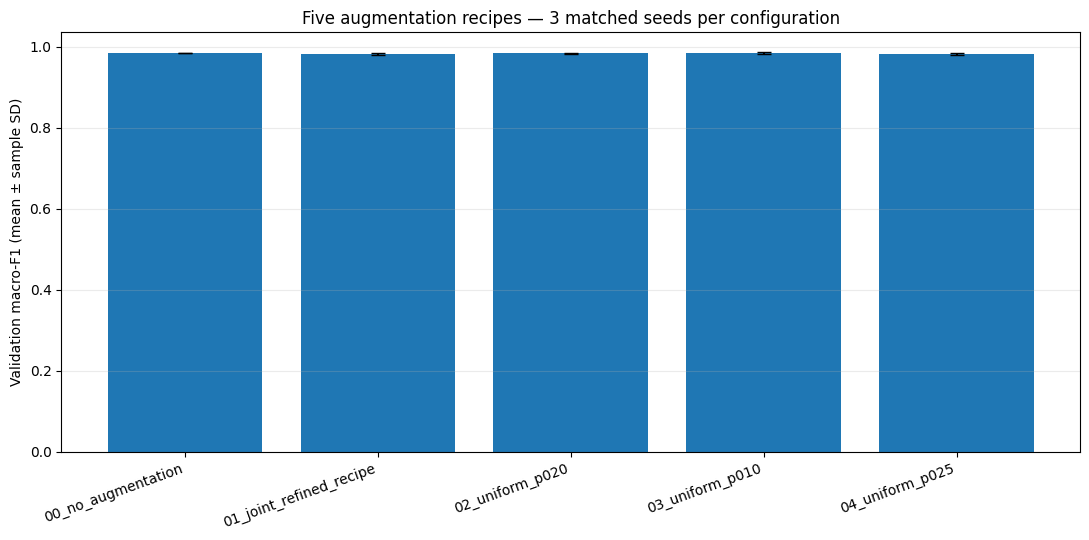

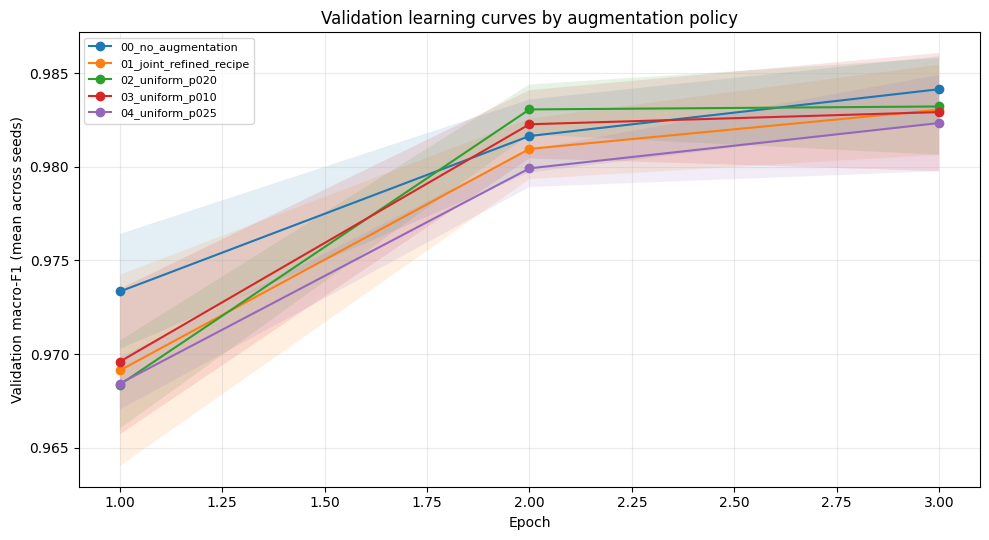

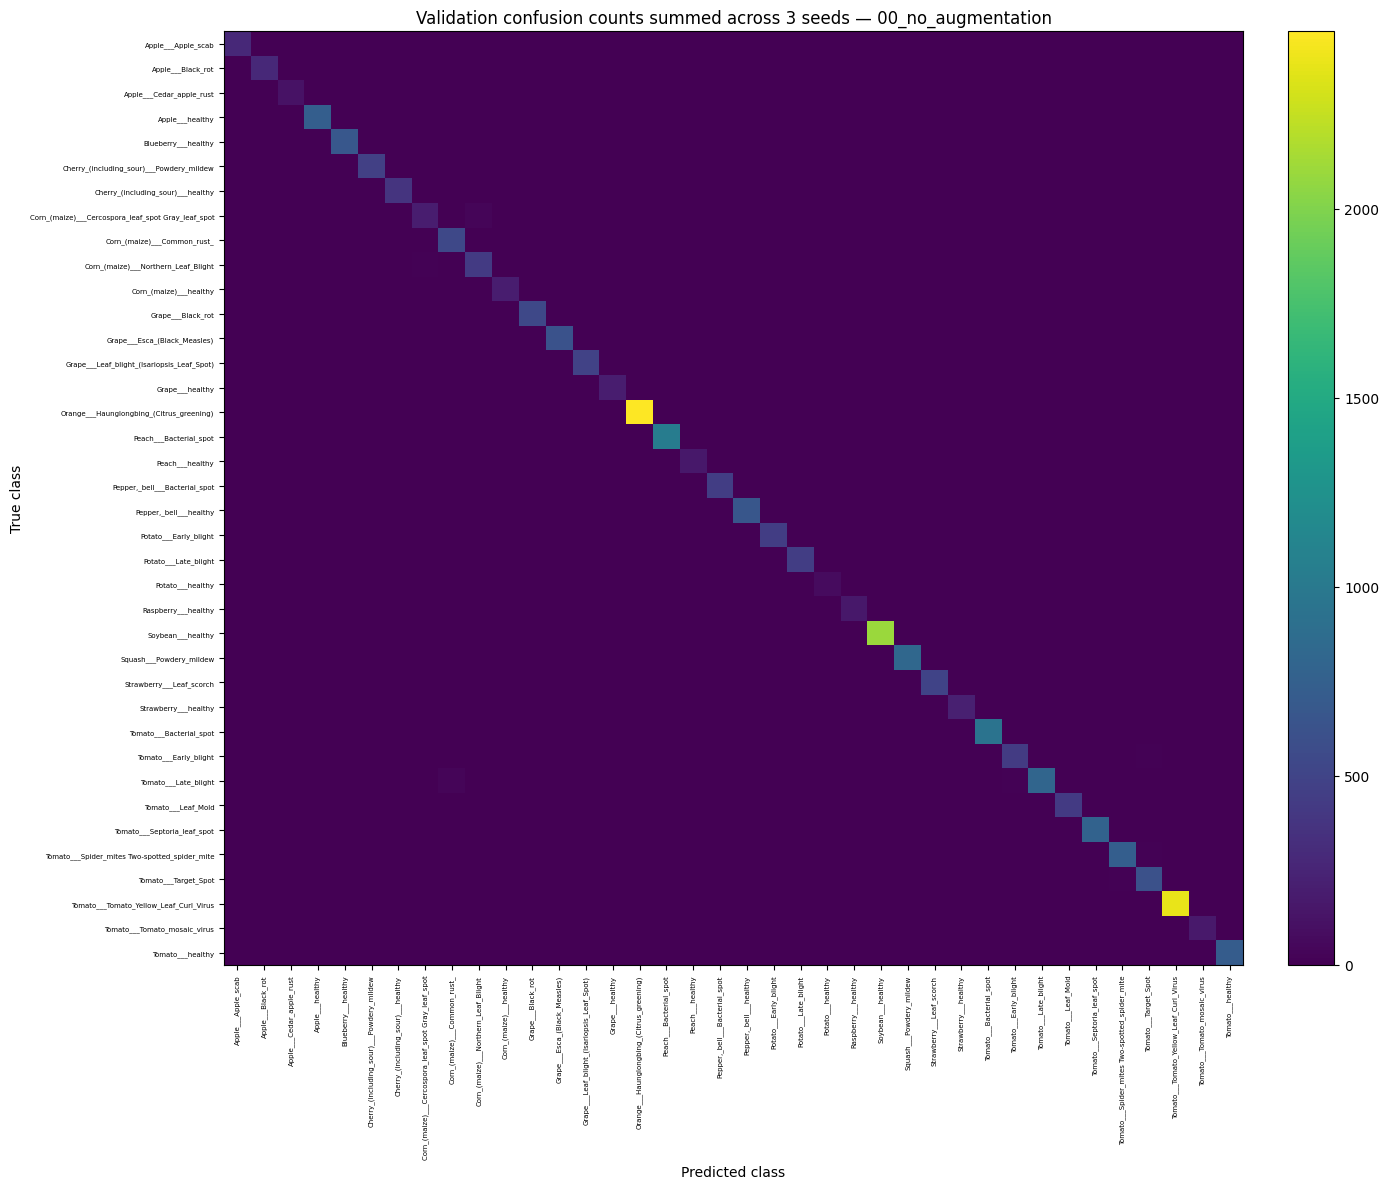

Saved plots:
 - /kaggle/working/terravista_augmentation_validation_study/runs/terravista-five-recipe-probability-comparison-v3.0_42d73726b034/plots/validation_macro_f1_mean_std.png
 - /kaggle/working/terravista_augmentation_validation_study/runs/terravista-five-recipe-probability-comparison-v3.0_42d73726b034/plots/validation_macro_f1_learning_curves.png
 - /kaggle/working/terravista_augmentation_validation_study/runs/terravista-five-recipe-probability-comparison-v3.0_42d73726b034/plots/selected_configuration_validation_confusion_matrix.png


In [11]:
if SEARCH_COMPLETE:
    plot_summary = summary_df.set_index("config_name").loc[[c["name"] for c in CONFIGS]].reset_index()
    fig, ax = plt.subplots(figsize=(11, 5.5))
    x = np.arange(len(plot_summary))
    ax.bar(
        x,
        plot_summary["val_macro_f1_mean"].to_numpy(),
        yerr=plot_summary["val_macro_f1_std"].fillna(0).to_numpy(),
        capsize=5,
    )
    ax.set_xticks(x)
    ax.set_xticklabels(plot_summary["config_name"], rotation=20, ha="right")
    ax.set_ylabel("Validation macro-F1 (mean ± sample SD)")
    ax.set_title("Five augmentation recipes — 3 matched seeds per configuration")
    ax.grid(axis="y", alpha=0.25)
    fig.tight_layout()
    main_plot_path = PLOT_DIR / "validation_macro_f1_mean_std.png"
    fig.savefig(main_plot_path, dpi=180, bbox_inches="tight")
    if IN_NOTEBOOK:
        plt.show()
    plt.close(fig)

    histories = []
    for cfg in CONFIGS:
        for seed in SEEDS:
            path = HISTORY_DIR / f"{cfg['name']}_seed{seed}.csv"
            if path.is_file():
                h = pd.read_csv(path)
                histories.append(h)
    if histories:
        history_df = pd.concat(histories, ignore_index=True)
        history_df.to_csv(RUN_DIR / "all_epoch_histories.csv", index=False)
        epoch_summary = (
            history_df.groupby(["config_name", "epoch"], as_index=False)
            .agg(macro_f1_mean=("val_macro_f1", "mean"), macro_f1_std=("val_macro_f1", "std"))
        )
        fig, ax = plt.subplots(figsize=(10, 5.5))
        for cfg in CONFIGS:
            sub = epoch_summary[epoch_summary["config_name"] == cfg["name"]]
            ax.plot(sub["epoch"], sub["macro_f1_mean"], marker="o", label=cfg["name"])
            sd = sub["macro_f1_std"].fillna(0).to_numpy()
            ax.fill_between(sub["epoch"].to_numpy(), sub["macro_f1_mean"].to_numpy() - sd,
                            sub["macro_f1_mean"].to_numpy() + sd, alpha=0.12)
        ax.set_xlabel("Epoch")
        ax.set_ylabel("Validation macro-F1 (mean across seeds)")
        ax.set_title("Validation learning curves by augmentation policy")
        ax.grid(alpha=0.25)
        ax.legend(fontsize=8)
        fig.tight_layout()
        curve_path = PLOT_DIR / "validation_macro_f1_learning_curves.png"
        fig.savefig(curve_path, dpi=180, bbox_inches="tight")
        if IN_NOTEBOOK:
            plt.show()
        plt.close(fig)

    fig, ax = plt.subplots(figsize=(14, 12))
    image = ax.imshow(summed_cm, interpolation="nearest", aspect="auto")
    ax.set_title(f"Validation confusion counts summed across 3 seeds — {SELECTED_CONFIG_NAME}")
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("True class")
    ax.set_xticks(np.arange(NUM_CLASSES))
    ax.set_yticks(np.arange(NUM_CLASSES))
    ax.set_xticklabels(CLASS_NAMES, rotation=90, fontsize=5)
    ax.set_yticklabels(CLASS_NAMES, fontsize=5)
    fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
    fig.tight_layout()
    cm_plot_path = PLOT_DIR / "selected_configuration_validation_confusion_matrix.png"
    fig.savefig(cm_plot_path, dpi=200, bbox_inches="tight")
    if IN_NOTEBOOK:
        plt.show()
    plt.close(fig)

    print("Saved plots:")
    print(" -", main_plot_path)
    print(" -", PLOT_DIR / "validation_macro_f1_learning_curves.png")
    print(" -", cm_plot_path)


## 9. Optional: train one selected model after the search

Complete and review all 15 validation runs first. This optional cell is off by default to avoid unexpectedly adding another long training job. When enabled, it trains the selected configuration with its training-only background masks if that configuration uses background variation. Validation is used for checkpoint selection; the test split remains untouched.

In [12]:
RUN_FINAL_MODEL_TRAINING = False  # Enable only after reviewing all five recipes on matched seeds.
FINAL_TRAINING_EPOCHS = 8
FINAL_EARLY_STOPPING_PATIENCE = 3
FINAL_MODEL_DIR = BASE_OUTPUT_DIR / "selected_final_model"
FINAL_MODEL_DIR.mkdir(parents=True, exist_ok=True)

if RUN_FINAL_MODEL_TRAINING:
    if not SEARCH_COMPLETE or SELECTED_CONFIG_NAME is None:
        raise RuntimeError("Complete the 15-run validation study and select a configuration first.")
    selected_config = CONFIG_BY_NAME[SELECTED_CONFIG_NAME]
    final_seed = SEEDS[0]
    reset_random_seeds(final_seed)
    final_model = build_resnet50()
    final_optimizer = make_optimizer(final_model)
    final_scaler = new_grad_scaler()
    final_train_loader = make_loader(
        TRAIN_POSITIONS, TRAIN_LABEL_IDS, train=True, seed=final_seed,
        include_background_masks=(selected_config["probabilities"]["p_background"] > 0.0),
    )
    final_val_loader = make_loader(VAL_POSITIONS, VAL_LABEL_IDS, train=False, seed=final_seed)
    best_state = None
    best_final_metrics = None
    no_improvement = 0
    final_history = []
    best_final_path = FINAL_MODEL_DIR / "resnet50_selected_augmentation_best_val.pt"

    for epoch in range(1, FINAL_TRAINING_EPOCHS + 1):
        started = time.time()
        train_metrics = train_one_epoch(final_model, final_train_loader, final_optimizer, final_scaler, selected_config)
        val_result = evaluate_model(final_model, final_val_loader)
        row = {
            "epoch": epoch,
            **train_metrics,
            **{k: v for k, v in val_result.items() if k not in {"y_true", "y_pred"}},
            "epoch_seconds": time.time() - started,
        }
        final_history.append(row)
        print(f"FINAL {epoch}/{FINAL_TRAINING_EPOCHS} | val macro-F1={row['val_macro_f1']:.4f} | val acc={row['val_accuracy']:.4f}")
        if best_final_metrics is None or row["val_macro_f1"] > best_final_metrics["val_macro_f1"]:
            best_final_metrics = row.copy()
            best_state = {k: v.detach().cpu().clone() for k, v in final_model.state_dict().items()}
            no_improvement = 0
            torch.save({
                "model_state_dict": best_state,
                "class_names": CLASS_NAMES,
                "image_size": IMG_SIZE,
                "selected_config": selected_config,
                "seed": final_seed,
                "best_epoch": epoch,
                "validation_metrics": {k: v for k, v in val_result.items() if k not in {"y_true", "y_pred"}},
                "test_split_touched": False,
            }, best_final_path)
            np.savez_compressed(FINAL_MODEL_DIR / "best_validation_predictions.npz",
                                y_true=val_result["y_true"], y_pred=val_result["y_pred"])
        else:
            no_improvement += 1
        pd.DataFrame(final_history).to_csv(FINAL_MODEL_DIR / "final_training_history.csv", index=False)
        if no_improvement >= FINAL_EARLY_STOPPING_PATIENCE:
            print("Early stopping: validation macro-F1 did not improve.")
            break

    final_model.load_state_dict(best_state)
    best_eval = evaluate_model(final_model, final_val_loader)
    final_metrics = {k: v for k, v in best_eval.items() if k not in {"y_true", "y_pred"}}
    final_metrics.update({"selected_config": SELECTED_CONFIG_NAME, "best_epoch": int(best_final_metrics["epoch"]), "test_split_touched": False})
    (FINAL_MODEL_DIR / "final_validation_metrics.json").write_text(json.dumps(final_metrics, indent=2))
    final_report = classification_report(
        best_eval["y_true"], best_eval["y_pred"], labels=list(range(NUM_CLASSES)),
        target_names=CLASS_NAMES, output_dict=True, zero_division=0,
    )
    pd.DataFrame(final_report).T.to_csv(FINAL_MODEL_DIR / "final_validation_classification_report.csv")
    pd.DataFrame(
        confusion_matrix(best_eval["y_true"], best_eval["y_pred"], labels=list(range(NUM_CLASSES))),
        index=CLASS_NAMES, columns=CLASS_NAMES,
    ).to_csv(FINAL_MODEL_DIR / "final_validation_confusion_matrix.csv")
    print("Saved selected final model:", best_final_path)
    print("Final validation metrics:", json.dumps(final_metrics, indent=2))
    del final_model, final_optimizer, final_scaler, final_train_loader, final_val_loader
    gc.collect()
    torch.cuda.empty_cache()
else:
    print("Optional final-model training is OFF. The 15-run (five recipes × three seeds) validation study is the required augmentation comparison.")
    print("To train the selected model later, set RUN_FINAL_MODEL_TRAINING=True in this cell and run this cell only.")


Optional final-model training is OFF. The 15-run (five recipes × three seeds) validation study is the required augmentation comparison.
To train the selected model later, set RUN_FINAL_MODEL_TRAINING=True in this cell and run this cell only.


## 10. Save a compact results bundle

The ZIP includes source/results/reports/plots only and excludes image cache, foreground-mask cache, and training checkpoints. No test metrics, test reports, test confusion matrices, or test predictions are produced.

In [13]:
if SEARCH_COMPLETE:
    results_zip = BASE_OUTPUT_DIR / f"terravista_augmentation_validation_results_{RUN_SIGNATURE}.zip"
    files_to_package = []
    for path in RUN_DIR.rglob("*"):
        if path.is_file() and "checkpoints" not in path.parts and not path.name.endswith(".tmp"):
            files_to_package.append(path)
    # Include final-model validation outputs only if that optional stage was run.
    if RUN_FINAL_MODEL_TRAINING:
        for path in FINAL_MODEL_DIR.rglob("*"):
            if path.is_file():
                files_to_package.append(path)
    with zipfile.ZipFile(results_zip, "w", compression=zipfile.ZIP_DEFLATED, compresslevel=6) as zf:
        for path in files_to_package:
            zf.write(path, arcname=str(path.relative_to(BASE_OUTPUT_DIR)))
    print("Results ZIP:", results_zip)
    print("Result files:")
    for name in [
        "augmentation_seed_results.csv",
        "augmentation_mean_std_summary.csv",
        "per_class_validation_metrics_mean_std.csv",
        "selected_configuration_per_class_validation_metrics.csv",
        "selected_configuration_validation_confusion_matrix_summed_seeds.csv",
        "all_augmentation_configurations.json",
        "best_augmented_configuration.json",
        "selected_augmentation_config.json",
        "augmentation_selection_summary.json",
        "augmentation_mean_std_summary.csv",
        "augmentation_paired_seed_deltas_vs_baseline.csv",
        "validation_macro_f1_mean_std.png",
        "selected_configuration_validation_confusion_matrix.png",
    ]:
        candidate = RUN_DIR / name
        if candidate.is_file():
            print(" -", candidate)
    print("All recipe JSONs are in:", CONFIG_JSON_DIR)
    print("No test-set metrics, test reports, test confusion matrices, or test predictions were produced.")
else:
    print(f"Results ZIP not created yet; finish all {len(CONFIGS) * len(SEEDS)} recipe/seed runs first.")


Results ZIP: /kaggle/working/terravista_augmentation_validation_study/terravista_augmentation_validation_results_42d73726b034.zip
Result files:
 - /kaggle/working/terravista_augmentation_validation_study/runs/terravista-five-recipe-probability-comparison-v3.0_42d73726b034/augmentation_seed_results.csv
 - /kaggle/working/terravista_augmentation_validation_study/runs/terravista-five-recipe-probability-comparison-v3.0_42d73726b034/augmentation_mean_std_summary.csv
 - /kaggle/working/terravista_augmentation_validation_study/runs/terravista-five-recipe-probability-comparison-v3.0_42d73726b034/per_class_validation_metrics_mean_std.csv
 - /kaggle/working/terravista_augmentation_validation_study/runs/terravista-five-recipe-probability-comparison-v3.0_42d73726b034/selected_configuration_per_class_validation_metrics.csv
 - /kaggle/working/terravista_augmentation_validation_study/runs/terravista-five-recipe-probability-comparison-v3.0_42d73726b034/selected_configuration_validation_confusion_matri